# Module 1: Product Analytics

### Business Objectives

The primary goal of this module is to evaluate product performance beyond surface-level Gross Merchandise Value (GMV). By analyzing conversion funnels across categories, brands, and price tiers (Premium vs. Non-Premium), we identify operational bottlenecks, high-intent drop-off categories, and potential quality/refund risks.

### Key Analytical Steps

1. **Category-Level Funnel Analysis**: Measure conversion rates from `view` -> `click` -> `cart` -> `purchase` per category to pinpoint drop-off friction.
2. **Product Tier Analysis**: Compare funnel efficiency between Premium and Non-Premium product lines.
3. **Product Health & Return Diagnosis**: Identify high-GMV product categories impacted by abnormally high refund rates.

In [1]:
# Import libraries for data manipulation, visualization,
# feature preprocessing, and predictive modeling.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor, XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

sns.set_theme(
    style = "whitegrid",
    context = "notebook",
    palette = "deep"
)

## 1.1 Product Portfolio & Category Performance

Evaluate product portfolio performance at the category level to identify major revenue drivers, conversion opportunities, and potential product-quality risks. Unless otherwise specified, the analysis excludes refunded transactions to focus on original sales performance. Net revenue and net units sold, which account for refunds, are provided separately in the summary table.

### Data Preparation

In [2]:
# Load cleaned datasets used for product and commercial analysis.
# The datasets are linked through customer_id, product_id, and campaign_id.
customers = pd.read_csv('/kaggle/input/datasets/gucliu/ecommerce-clean-processed-data/customers_clean.csv')
transactions = pd.read_csv('/kaggle/input/datasets/gucliu/ecommerce-clean-processed-data/transactions_clean.csv')
events = pd.read_csv('/kaggle/input/datasets/gucliu/ecommerce-clean-processed-data/events_clean.csv')
products = pd.read_csv('/kaggle/input/datasets/gucliu/ecommerce-clean-processed-data/products_clean.csv')
campaigns = pd.read_csv('/kaggle/input/datasets/gucliu/ecommerce-clean-processed-data/campaigns_clean.csv')

# Review dataset dimensions before analysis.
print("Customers shape:", customers.shape)
print("Transactions shape:", transactions.shape)
print("Events shape:", events.shape)
print("Products shape:", products.shape)
print("Campaigns shape:", campaigns.shape)

Customers shape: (100000, 7)
Transactions shape: (92678, 10)
Events shape: (2000000, 12)
Products shape: (2000, 6)
Campaigns shape: (50, 7)


In [3]:
# Add product attributes to event and transaction data
# for category, brand, pricing, and premium-product analysis.
event_prod = events.merge(
    products[['product_id', 'category', 'brand', 'base_price', 'is_premium']],
    on = 'product_id',
    how = 'left'
)

trans_prod = transactions.merge(
    products[['product_id', 'category', 'brand', 'base_price', 'is_premium']],
    on = 'product_id',
    how = 'left'
)

# Create a readable product-tier label for Premium vs. Non-Premium analysis.
event_prod['product_segment'] = event_prod['is_premium'].map({1: 'Premium', 0: 'Non-Premium'})
trans_prod['product_segment'] = trans_prod['is_premium'].map({1: 'Premium', 0: 'Non-Premium'})

### 1.1.1 Category Sales Performance

In [4]:
# Create category-level sales metrics
category_sales = (
    trans_prod.groupby('category')
    .agg(
        total_gmv = (
            'gross_revenue',
            lambda s: s[~trans_prod.loc[s.index, 'is_refund']].sum()
        ),
        purchase_transactions = (
            'is_refund',
            lambda s: (~s).sum()
        ),
        total_units_sold = (
            'quantity',
            lambda s: s[~trans_prod.loc[s.index, 'is_refund']].sum()
        ),
        refund_transactions = ('is_refund', 'sum'),
        net_revenue = ('gross_revenue', 'sum')
    )
    .reset_index()
)

# Calculate net units sold separately
net_units = (
    trans_prod.assign(
        signed_quantity = trans_prod['quantity'].where(
            ~trans_prod['is_refund'],
            -trans_prod['quantity']
        )
    )
    .groupby('category')['signed_quantity']
    .sum()
)

category_sales['net_units_sold'] = (
    category_sales['category'].map(net_units)
)

# Calculate refund transaction ratio
category_sales['refund_transaction_ratio_%'] = (
    category_sales['refund_transactions']
    / category_sales['purchase_transactions']
    * 100
)

# Calculate average purchase transaction value
category_sales['avg_purchase_transaction_value'] = (
    category_sales['total_gmv']
    / category_sales['purchase_transactions']
)

# Calculate GMV share
category_sales['gmv_share_%'] = (
    category_sales['total_gmv']
    / category_sales['total_gmv'].sum()
    * 100
)

# Sort by GMV
category_sales = category_sales.sort_values(
    'total_gmv', ascending = False
).reset_index(drop = True)

display(
    category_sales.style.format({
        'total_gmv': '${:,.2f}',
        'purchase_transactions': '{:,.0f}',
        'total_units_sold': '{:,.0f}',
        'refund_transactions': '{:,.0f}',
        'net_revenue': '${:,.2f}',
        'net_units_sold': '{:,.0f}',
        'refund_transaction_ratio_%': '{:.2f}%',
        'avg_purchase_transaction_value': '${:,.2f}',
        'gmv_share_%': '{:.2f}%'
    })
)

,category,total_gmv,purchase_transactions,total_units_sold,refund_transactions,net_revenue,net_units_sold,refund_transaction_ratio_%,avg_purchase_transaction_value,gmv_share_%
0,Electronics,"$3,554,175.61","20,469","28,347",626,"$3,452,007.19","27,500",3.06%,$173.64,41.18%
1,Home,"$2,053,954.96","17,914","24,549",507,"$1,996,432.94","23,860",2.83%,$114.66,23.80%
2,Fashion,"$1,338,781.78","18,799","26,058",540,"$1,298,075.77","25,291",2.87%,$71.22,15.51%
3,Sports,"$1,000,708.47","9,839","13,697",329,"$965,609.13","13,219",3.34%,$101.71,11.60%
4,Beauty,"$381,439.05","8,938","12,302",286,"$369,671.88","11,918",3.20%,$42.68,4.42%
5,Grocery,"$301,209.44","14,015","19,335",416,"$292,169.45","18,740",2.97%,$21.49,3.49%


### GMV by Product Category

GMV is used as the primary measure of category-level sales contribution, based on purchase transactions excluding refunds.

A category with high GMV may represent a major business driver, while a category with relatively low GMV may require further investigation to determine whether the issue is low demand, low traffic, low conversion, or low average transaction value.

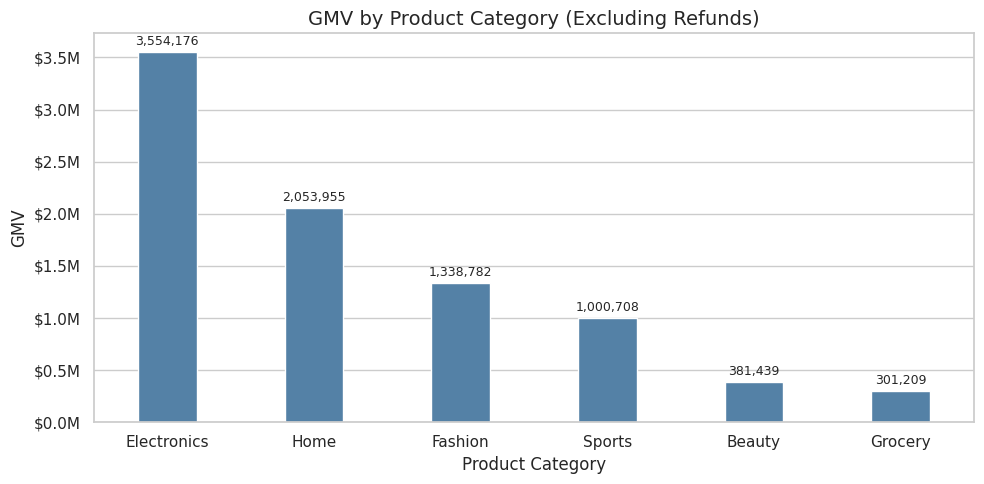

In [5]:
# Visualization of categories by GMV
plt.figure(figsize = (10, 5))

ax = sns.barplot(
    data = category_sales, 
    x = 'category', 
    y = 'total_gmv', 
    color = 'steelblue',
    width = 0.4
)

plt.title('GMV by Product Category (Excluding Refunds)', fontsize = 14)
plt.xlabel('Product Category')

ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'${x / 1e6:.1f}M')
)
plt.ylabel('GMV')

# Add GMV labels on top of each bar
ax.bar_label(
    ax.containers[0],
    fmt = lambda x: f'{x:,.0f}',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### Purchase Transaction Volume and Average Transaction Value
Revenue scale alone does not fully describe category performance.

Purchase transaction volume and average transaction value are used together to distinguish categories driven by higher transaction frequency from those driven by higher-value transactions.

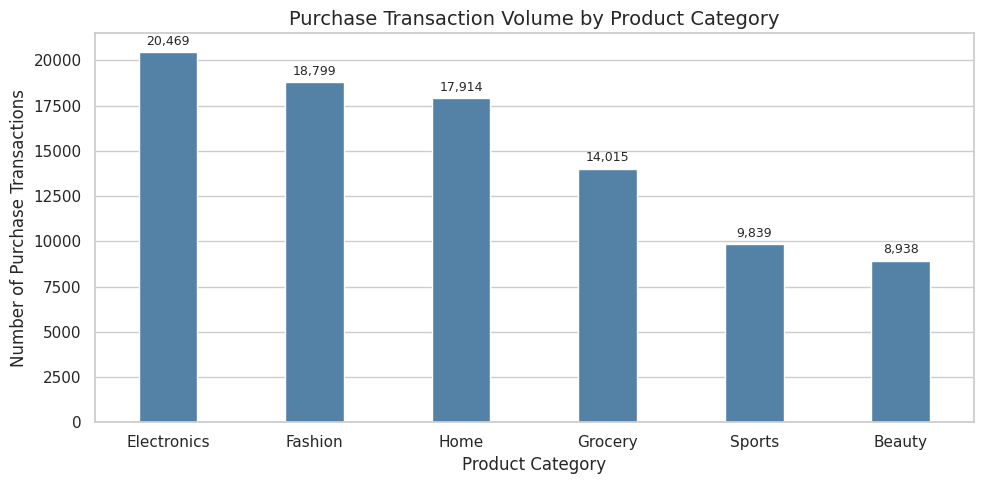

In [6]:
# Create a copy sorted by purchase transaction volume
order_data = category_sales.sort_values(
    'purchase_transactions',
    ascending = False
)

plt.figure(figsize = (10, 5))

ax = sns.barplot(
    data = order_data,
    x = 'category',
    y = 'purchase_transactions',
    color = 'steelblue',
    width = 0.4
)

plt.title(
    'Purchase Transaction Volume by Product Category',
    fontsize = 14
)
plt.xlabel('Product Category')
plt.ylabel('Number of Purchase Transactions')

# Add transaction counts on top of each bar
ax.bar_label(
    ax.containers[0],
    fmt = lambda x: f'{x:,.0f}',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

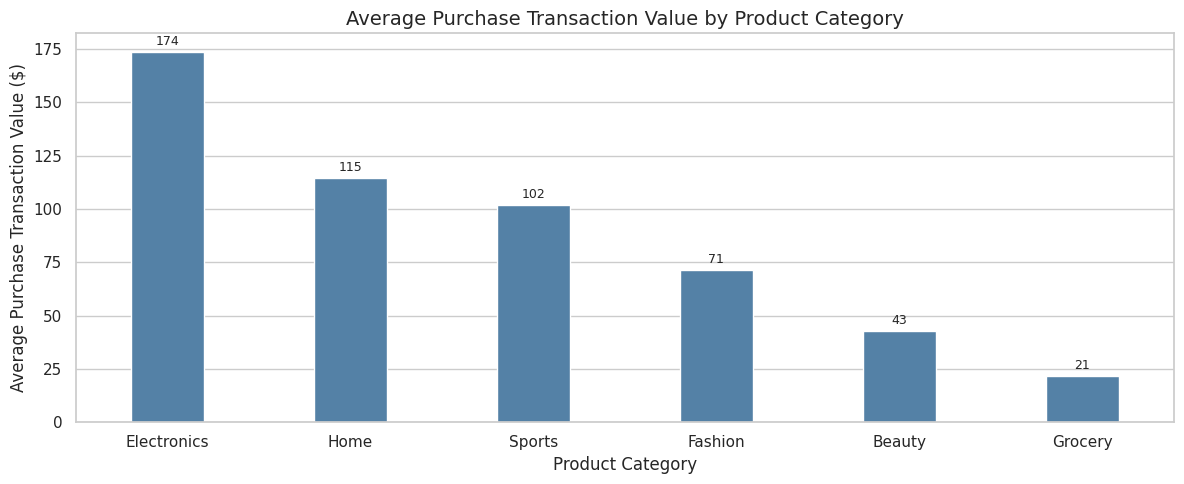

In [7]:
# Sort categories by average purchase transaction value
aov_data = category_sales.sort_values(
    'avg_purchase_transaction_value',
    ascending = False
)

plt.figure(figsize = (12, 5))

ax = sns.barplot(
    data = aov_data,
    x = 'category',
    y = 'avg_purchase_transaction_value',
    color = 'steelblue',
    width = 0.4
)

plt.title(
    'Average Purchase Transaction Value by Product Category',
    fontsize = 14
)
plt.xlabel('Product Category')
plt.ylabel('Average Purchase Transaction Value ($)')

ax.bar_label(
    ax.containers[0],
    fmt = lambda x: f'{x:,.0f}',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### 1.1.2 Category-Level Product Conversion

For each category, product conversion rate is calculated as:

**Conversion Rate = Unique Customer Who Purchased / Unique Customers Who Viewed**

Unique customers are used rather than event counts to prevent repeated product interactions from inflating conversion rates.

In [8]:
# Keep only product-related funnel events
category_funnel_data = event_prod[
    event_prod['event_type'].isin(['view', 'purchase'])
].copy()

# Count unique customers at each funnel stage for each category
category_conversion = (
    category_funnel_data
    .groupby(['category', 'event_type'])['customer_id']
    .nunique()
    .unstack(fill_value = 0)
    .reset_index()
)

for col in ['view', 'purchase']:
    if col not in category_conversion.columns:
        category_conversion[col] = 0

# Calculate view-to-purchase conversion rate
category_conversion['conversion_rate_%'] = (
    category_conversion['purchase'] / 
    category_conversion['view'] * 
    100
).round(2)

display(
    category_conversion.style.format({
        'view': '{:,.0f}',
        'purchase': '{:,.0f}',
        'conversion_rate_%': '{:.2f}%'
    })
)

event_type,category,purchase,view,conversion_rate_%
0,Beauty,"8,801","65,062",13.53%
1,Electronics,"18,897","90,690",20.84%
2,Fashion,"17,560","88,730",19.79%
3,Grocery,"13,390","80,204",16.69%
4,Home,"16,793","87,427",19.21%
5,Sports,"9,652","67,916",14.21%


In [9]:
# Merge category conversion metrics into the main category performance table
category_sales = category_sales.merge(
    category_conversion[
        ['category', 'view', 'purchase', 'conversion_rate_%']
    ],
    on = 'category',
    how = 'left'
)

category_sales = category_sales.rename(
    columns = {
        'view': 'unique_viewers',
        'purchase': 'unique_purchasers'
    }
)

# Display category performance metrics
display(
    category_sales.style.format({
        'total_gmv': '${:,.2f}',
        'purchase_transactions': '{:,.0f}',
        'total_units_sold': '{:,.0f}',
        'refund_transactions': '{:,.0f}',
        'net_revenue': '${:,.2f}',
        'net_units_sold': '{:,.0f}',
        'refund_transaction_ratio_%': '{:.2f}%',
        'avg_purchase_transaction_value': '${:,.2f}',
        'gmv_share_%': '{:.2f}%',
        'unique_viewers': '{:,.0f}',
        'unique_purchasers': '{:,.0f}',
        'conversion_rate_%': '{:.2f}%'
    })
)

,category,total_gmv,purchase_transactions,total_units_sold,refund_transactions,net_revenue,net_units_sold,refund_transaction_ratio_%,avg_purchase_transaction_value,gmv_share_%,unique_viewers,unique_purchasers,conversion_rate_%
0,Electronics,"$3,554,175.61","20,469","28,347",626,"$3,452,007.19","27,500",3.06%,$173.64,41.18%,"90,690","18,897",20.84%
1,Home,"$2,053,954.96","17,914","24,549",507,"$1,996,432.94","23,860",2.83%,$114.66,23.80%,"87,427","16,793",19.21%
2,Fashion,"$1,338,781.78","18,799","26,058",540,"$1,298,075.77","25,291",2.87%,$71.22,15.51%,"88,730","17,560",19.79%
3,Sports,"$1,000,708.47","9,839","13,697",329,"$965,609.13","13,219",3.34%,$101.71,11.60%,"67,916","9,652",14.21%
4,Beauty,"$381,439.05","8,938","12,302",286,"$369,671.88","11,918",3.20%,$42.68,4.42%,"65,062","8,801",13.53%
5,Grocery,"$301,209.44","14,015","19,335",416,"$292,169.45","18,740",2.97%,$21.49,3.49%,"80,204","13,390",16.69%


### 1.1.3 Refund Transaction Ratio by Product Category

The refund transaction ratio provides an additional view of product performance and potential customer-experience issues.

Categories with relatively high sales revenue and elevated refund transaction ratios may warrant further investigation into product quality, pricing, customer expectations, or fulfillment.

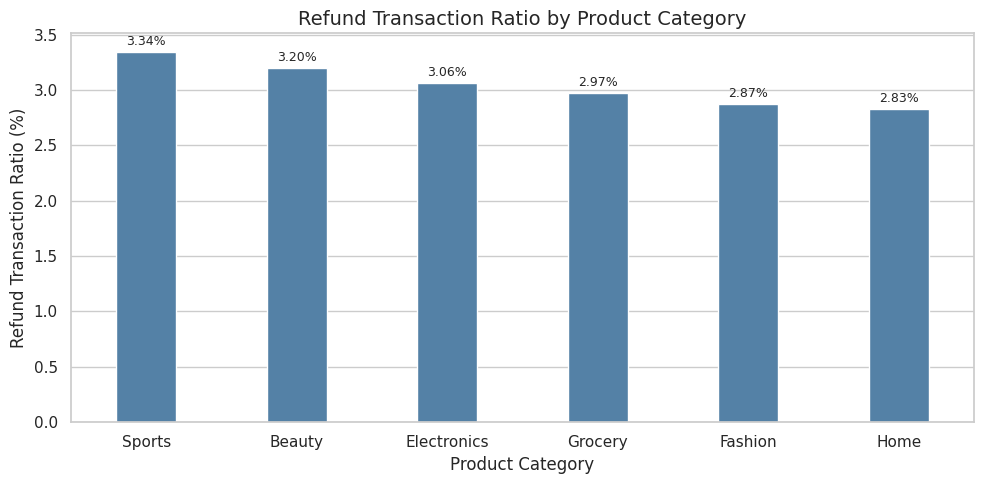

In [10]:
# Sort categories by refund transaction ratio
refund_data = category_sales.sort_values(
    'refund_transaction_ratio_%',
    ascending = False
)

plt.figure(figsize = (10, 5))

ax = sns.barplot(
    data = refund_data,
    x = 'category',
    y = 'refund_transaction_ratio_%',
    color = 'steelblue',
    width = 0.4
)

plt.title(
    'Refund Transaction Ratio by Product Category',
    fontsize = 14
)
plt.xlabel('Product Category')
plt.ylabel('Refund Transaction Ratio (%)')

ax.bar_label(
    ax.containers[0],
    fmt = '%.2f%%',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### 1.1.4 Category Performance Matrix

GMV and conversion rate provide complementary perspectives on category performance.

The matrix below identifies four types of categories:

- **High GMV + High Conversion**: Core categories with both scale and efficiency
- **High GMV + Low Conversion**: Major revenue contributors with potential conversion opportunities
- **Low GMV + High Conversion**: Efficient categories with potential for additional traffic or exposure
- **Low GMV + Low Conversion**: Categories that may require further investigation

Refund transaction ratio is reviewed alongside the matrix to identify potential product-quality or customer-experience risks.

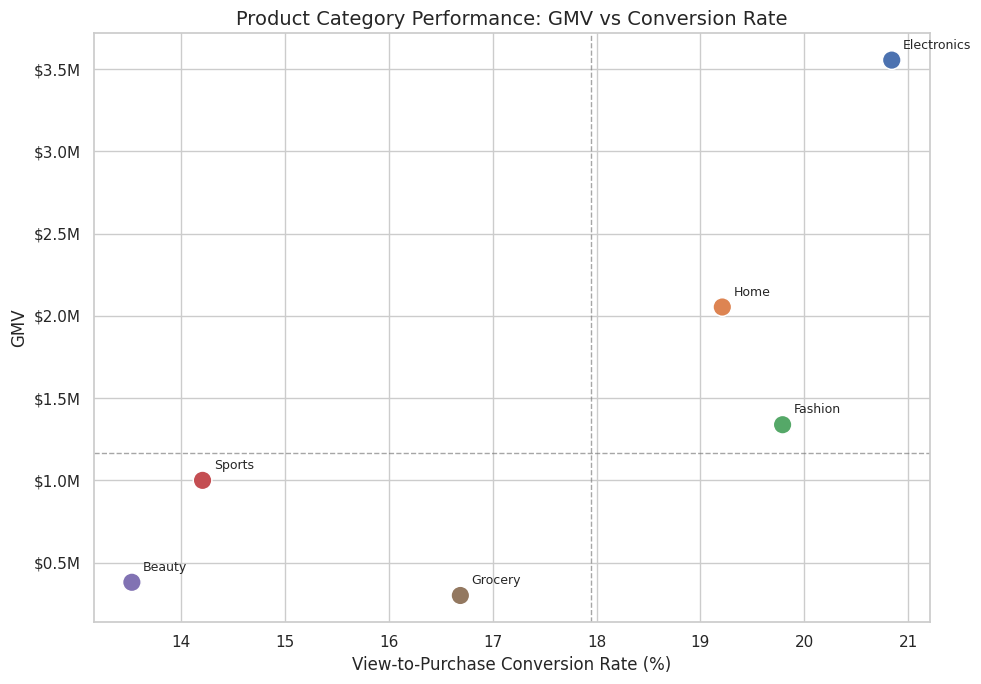

In [11]:
# Calculate median thresholds to classify category performance
gmv_threshold = category_sales['total_gmv'].median()
conversion_threshold = category_sales['conversion_rate_%'].median()

plt.figure(figsize = (10, 7))

# Create scatter plot
ax = sns.scatterplot(
    data = category_sales,
    x = 'conversion_rate_%',
    y = 'total_gmv',
    hue = 'category',
    s = 180,
    palette = 'deep',
    legend = False
)

# Add category labels
for _, row in category_sales.iterrows():
    ax.annotate(
        row['category'],
        (row['conversion_rate_%'], row['total_gmv']),
        xytext = (8, 6),
        textcoords = 'offset points',
        fontsize = 9,
        ha = 'left',
        va = 'bottom'
    )

# Add median reference lines
ax.axvline(
    conversion_threshold,
    color = 'gray',
    linestyle = '--',
    linewidth = 1,
    alpha = 0.7
)

ax.axhline(
    gmv_threshold,
    color = 'gray',
    linestyle = '--',
    linewidth = 1,
    alpha = 0.7
)

# Format y-axis in millions of dollars
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'${x / 1e6:.1f}M')
)

plt.title(
    'Product Category Performance: GMV vs Conversion Rate',
    fontsize = 14
)
plt.xlabel('View-to-Purchase Conversion Rate (%)')
plt.ylabel('GMV')

plt.tight_layout()
plt.show()

In [12]:
# Classify categories based on GMV and conversion performance
def classify_category(row):
    
    high_gmv = row['total_gmv'] >= gmv_threshold
    high_conversion = row['conversion_rate_%'] >= conversion_threshold
    
    if high_gmv and high_conversion:
        return 'High GMV / High Conversion'
    
    elif high_gmv and not high_conversion:
        return 'High GMV / Low Conversion'
    
    elif not high_gmv and high_conversion:
        return 'Low GMV / High Conversion'
    
    else:
        return 'Low GMV / Low Conversion'


# Apply the classification
category_sales['performance_segment'] = (
    category_sales.apply(
        classify_category,
        axis = 1
    )
)

# Display category performance segments
display(
    category_sales[
        [
            'category',
            'total_gmv',
            'gmv_share_%',
            'conversion_rate_%',
            'refund_transaction_ratio_%',
            'performance_segment'
        ]
    ]
    .sort_values(
        'total_gmv',
        ascending = False
    )
    .style.format({
        'total_gmv': '${:,.2f}',
        'gmv_share_%': '{:.2f}%',
        'conversion_rate_%': '{:.2f}%',
        'refund_transaction_ratio_%': '{:.2f}%'
    })
)

,category,total_gmv,gmv_share_%,conversion_rate_%,refund_transaction_ratio_%,performance_segment
0,Electronics,"$3,554,175.61",41.18%,20.84%,3.06%,High GMV / High Conversion
1,Home,"$2,053,954.96",23.80%,19.21%,2.83%,High GMV / High Conversion
2,Fashion,"$1,338,781.78",15.51%,19.79%,2.87%,High GMV / High Conversion
3,Sports,"$1,000,708.47",11.60%,14.21%,3.34%,Low GMV / Low Conversion
4,Beauty,"$381,439.05",4.42%,13.53%,3.20%,Low GMV / Low Conversion
5,Grocery,"$301,209.44",3.49%,16.69%,2.97%,Low GMV / Low Conversion


### Key Findings

- Revenue Driver: Electronics is the largest category, contributing 41.18% of total GMV, followed by Home at 23.80%.
- High-Value Category: Electronics also has the highest average purchase transaction value at approximately $173.64 per order.
- Conversion: Category-level conversion differences are relatively smaller than the differences in GMV, suggesting that revenue scale is influenced strongly by transaction value and sales volume.
- Refund Risk: Sports has the highest refund transaction ratio at approximately 3.34%, although the overall refund-transaction-ratio differences across categories are relatively small.
### Business Implications

Category prioritization should consider revenue scale, conversion efficiency, and refund risk together, rather than relying on GMV alone.

## 1.2 Product Conversion Funnel

Analyze the customer journey from product view to purchase to identify major drop-off points and category-level conversion opportunities.

The funnel is defined as View → Click → Add to Cart → Purchase, with conversion and drop-off rates calculated at the unique customer level. This approach avoids over-counting repeated interactions and provides a customer-centric view of funnel performance.

### Funnel Data Preparation


In [13]:
# Define the funnel stages in their intended customer journey order
funnel_steps = ['view', 'click', 'add_to_cart', 'purchase']

# Keep only events that belong to the product conversion funnel
funnel_data = event_prod[
    event_prod['event_type'].isin(funnel_steps)
].copy()

# Display the number of records retained for the funnel analysis
print("Funnel data shape:", funnel_data.shape)

# Show the available funnel event types
print("\nFunnel event types:")
print(funnel_data['event_type'].value_counts())

Funnel data shape: (1810078, 17)

Funnel event types:
event_type
view           1043573
click           379008
add_to_cart     284370
purchase        103127
Name: count, dtype: int64


### 1.2.1 Overall Product Conversion Funnel

Measure the number of unique customers reaching each stage of the product purchase journey.

The analysis focuses on both overall conversion and stage-to-stage conversion to identify the primary funnel bottleneck.

In [14]:
# Count unique customers at each funnel stage
overall_funnel = (
    funnel_data
    .groupby('event_type')['customer_id']
    .nunique()
    .reindex(funnel_steps)
)

# Convert the series into a DataFrame
funnel_df = overall_funnel.reset_index()

# Rename columns for readability
funnel_df.columns = [
    'funnel_stage',
    'unique_customers'
]

# Calculate overall conversion rate relative to the first funnel stage
funnel_df['overall_conversion_%'] = (
    funnel_df['unique_customers'] / 
    funnel_df['unique_customers'].iloc[0] * 
    100
)

# Calculate step-by-step conversion rate
funnel_df['step_conversion_%'] = (
    funnel_df['unique_customers'] / 
    funnel_df['unique_customers'].shift(1) *
    100
)

# Calculate drop-off rate between consecutive stages
funnel_df['dropoff_%'] = (
    100 -
    funnel_df['step_conversion_%']
)
# The first stage's step conversion and drop-off are not applicable
funnel_df.loc[0, 'step_conversion_%'] = np.nan
funnel_df.loc[0, 'dropoff_%'] = np.nan

# Round percentage metrics
funnel_df[
    [
        'overall_conversion_%',
        'step_conversion_%',
        'dropoff_%'
    ]
] = funnel_df[
    [
        'overall_conversion_%',
        'step_conversion_%',
        'dropoff_%'
    ]
].round(2)

display(
    funnel_df.style.format({
        'unique_customers': '{:,.0f}',
        'overall_conversion_%': '{:.2f}%',
        'step_conversion_%': '{:.2f}%',
        'dropoff_%': '{:.2f}%'
    }, na_rep = '—')
)

,funnel_stage,unique_customers,overall_conversion_%,step_conversion_%,dropoff_%
0,view,"99,997",100.00%,—,—
1,click,"97,725",97.73%,97.73%,2.27%
2,add_to_cart,"94,228",94.23%,96.42%,3.58%
3,purchase,"64,035",64.04%,67.96%,32.04%


### Overall Funnel Visualization

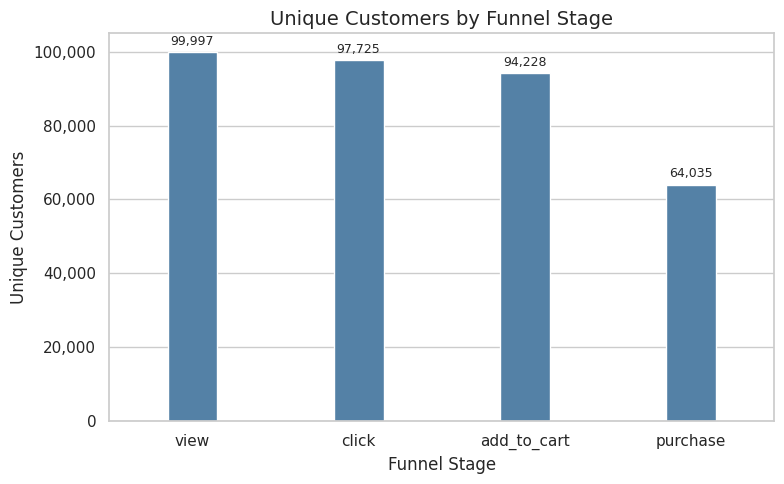

In [15]:
# Create a bar chart showing unique customers at each funnel stage
plt.figure(figsize = (8, 5))

ax = sns.barplot(
    data = funnel_df,
    x = 'funnel_stage',
    y = 'unique_customers',
    color = 'steelblue',
    width = 0.3
)

plt.title(
    'Unique Customers by Funnel Stage',
    fontsize = 14
)
plt.xlabel('Funnel Stage')

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)
plt.ylabel('Unique Customers')

ax.bar_label(
    ax.containers[0],
    fmt = lambda x: f'{x:,.0f}',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### Stage Conversion Rate

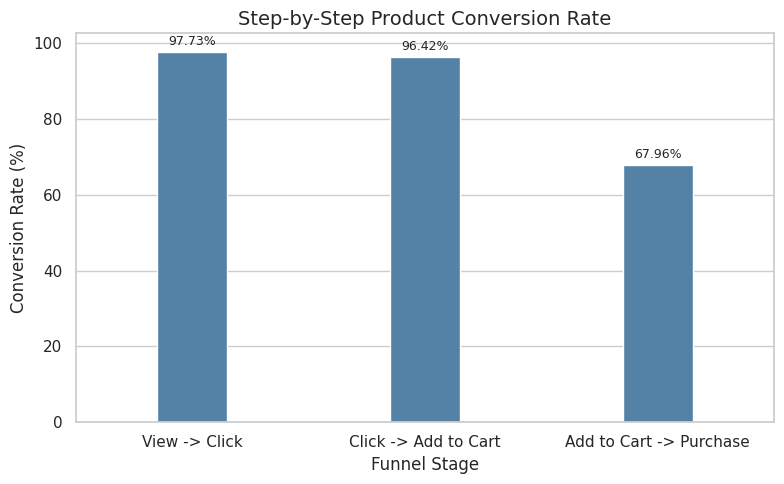

In [16]:
# Create a copy containing only stages after the initial view
step_conversion = funnel_df.iloc[1:].copy()

# Create readable labels for each funnel transition
step_conversion['transition'] = [
    'View -> Click',
    'Click -> Add to Cart',
    'Add to Cart -> Purchase'
]

plt.figure(figsize = (8, 5))

ax = sns.barplot(
    data = step_conversion,
    x = 'transition',
    y = 'step_conversion_%',
    color = 'steelblue',
    width = 0.3
)

plt.title(
    'Step-by-Step Product Conversion Rate',
    fontsize = 14
)
plt.xlabel('Funnel Stage')
plt.ylabel('Conversion Rate (%)')

ax.bar_label(
    ax.containers[0],
    fmt = '%.2f%%',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### Funnel Drop-off Analysis

Identify the transition with the largest customer loss.

The largest drop-off stage represents the most immediate opportunity for product-page, pricing, cart, or checkout optimization.

In [17]:
# Identify the funnel transition with the highest drop-off rate.
largest_dropoff = (
    step_conversion.loc[
        step_conversion['dropoff_%'].idxmax()
    ]
)

dropoff_summary = pd.DataFrame({
    'Metric': [
        'Largest Drop-off Stage',
        'Drop-off Rate'
    ],
    'Value': [
        largest_dropoff['transition'],
        f"{largest_dropoff['dropoff_%']:.2f}%"
    ]
})

dropoff_summary

,Metric,Value
0,Largest Drop-off Stage,Add to Cart -> Purchase
1,Drop-off Rate,32.04%


### 1.2.2 Category-Level Funnel Analysis

Compare funnel performance across product categories to identify categories with strong customer interest, efficient conversion, or larger stage-specific drop-offs.

In [18]:
# Count unique customers at each funnel stage by product category
category_funnel = (
    funnel_data.groupby(
        ['category', 'event_type']
    )['customer_id']
    .nunique().unstack(fill_value = 0)
)

existing_steps = [
    step
    for step in funnel_steps
    if step in category_funnel.columns
]

category_funnel = category_funnel[
    existing_steps
]

# Calculate overall conversion rate relative to product views
first_step = existing_steps[0]
for step in existing_steps:
    category_funnel[
        f'{step}_overall_conv_%'
    ] = (
        category_funnel[step] / 
        category_funnel[first_step] * 
        100
    )

# Calculate step-by-step conversion rates
for i in range(1, len(existing_steps)):
    current_step = existing_steps[i]
    previous_step = existing_steps[i-1]
    category_funnel[
        f'{previous_step}_to_{current_step}_conv_%'
    ] = (
        category_funnel[current_step] /
        category_funnel[previous_step] * 
        100
    )

category_funnel_df = (
    category_funnel
    .reset_index()
)

# Round percentage metrics
percentage_columns = [
    col
    for col in category_funnel_df.columns
    if '_conv_%' in col
]
category_funnel_df[
    percentage_columns
] = category_funnel_df[
    percentage_columns
].round(2)

# Display category-level funnel metrics
format_dict = {
    col: '{:,.0f}'
    for col in existing_steps
}

format_dict.update({
    col: '{:.2f}%'
    for col in percentage_columns
})

display(
    category_funnel_df.style.format(
        format_dict,
        na_rep = '—'
    )
)

event_type,category,view,click,add_to_cart,purchase,view_overall_conv_%,click_overall_conv_%,add_to_cart_overall_conv_%,purchase_overall_conv_%,view_to_click_conv_%,click_to_add_to_cart_conv_%,add_to_cart_to_purchase_conv_%
0,Beauty,"65,062","31,782","24,932","8,801",100.00%,48.85%,38.32%,13.53%,48.85%,78.45%,35.30%
1,Electronics,"90,690","57,738","47,409","18,897",100.00%,63.67%,52.28%,20.84%,63.67%,82.11%,39.86%
2,Fashion,"88,730","55,026","44,955","17,560",100.00%,62.02%,50.66%,19.79%,62.02%,81.70%,39.06%
3,Grocery,"80,204","44,716","35,775","13,390",100.00%,55.75%,44.61%,16.69%,55.75%,80.00%,37.43%
4,Home,"87,427","52,540","42,931","16,793",100.00%,60.10%,49.10%,19.21%,60.10%,81.71%,39.12%
5,Sports,"67,916","33,836","26,737","9,652",100.00%,49.82%,39.37%,14.21%,49.82%,79.02%,36.10%


### Category Funnel Conversion Heatmap

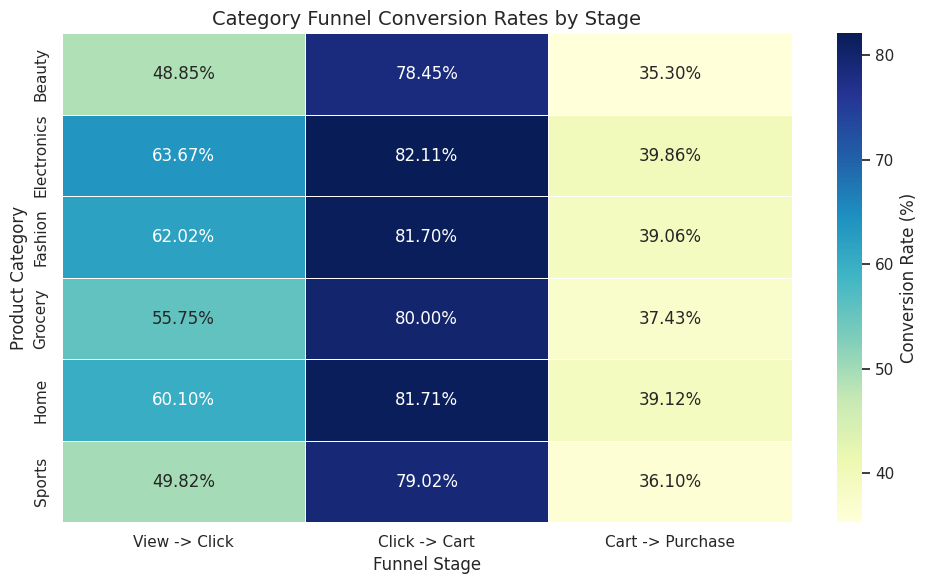

In [19]:
# Select the step-by-step conversion metrics for visualization
step_conv_cols = [
    'view_to_click_conv_%',
    'click_to_add_to_cart_conv_%',
    'add_to_cart_to_purchase_conv_%'
]

# Define readable names for each conversion step
column_names = {
    'view_to_click_conv_%': 'View -> Click',
    'click_to_add_to_cart_conv_%': 'Click -> Cart',
    'add_to_cart_to_purchase_conv_%': 'Cart -> Purchase'
}

# Keep only columns that are available in the dataset
step_conv_cols = [
    col
    for col in step_conv_cols
    if col in category_funnel_df.columns
]

# Create heatmap data
heatmap_data = (
    category_funnel_df
    .set_index('category')[step_conv_cols]
    .rename(columns = column_names)
)

# Create heatmap
plt.figure(figsize = (10, 6))

# Add percentage signs to cell annotations
annotations = heatmap_data.map(
    lambda x: f'{x:.2f}%'
)

ax = sns.heatmap(
    heatmap_data,
    annot = annotations,
    fmt = '',
    cmap = 'YlGnBu',
    linewidths = 0.5,
    cbar_kws = {
        'label': 'Conversion Rate (%)'
    }
)

plt.title(
    'Category Funnel Conversion Rates by Stage',
    fontsize = 14
)
plt.xlabel('Funnel Stage')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

### View-to-Purchase Conversion by Category

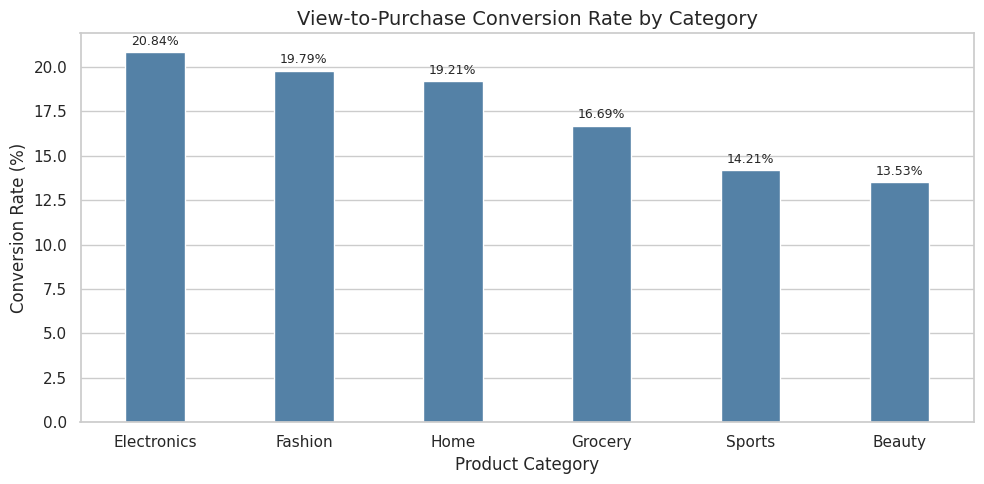

In [20]:
# Select category-level overall conversion rate
category_conversion_plot = (
    category_funnel_df[
        [
            'category',
            'purchase_overall_conv_%'
        ]
    ]
    .sort_values(
        'purchase_overall_conv_%',
        ascending = False
    )
)

plt.figure(figsize = (10, 5))

ax = sns.barplot(
    data = category_conversion_plot,
    x = 'category',
    y = 'purchase_overall_conv_%',
    color = 'steelblue',
    width = 0.4
)

plt.title(
    'View-to-Purchase Conversion Rate by Category',
    fontsize = 14
)
plt.xlabel('Product Category')
plt.ylabel('Conversion Rate (%)')

   
ax.bar_label(
    ax.containers[0],
    fmt = '%.2f%%',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### 1.2.3 Integrated Category Performance

Combine category-level GMV, conversion, average transaction value, and refund metrics to identify categories that should be prioritized for growth, conversion optimization, or product-quality investigation.

In [21]:
# Select the most relevant category-level metrics from Module 1
category_summary = category_sales[
    [
        'category',
        'total_gmv',
        'gmv_share_%',
        'avg_purchase_transaction_value',
        'refund_transaction_ratio_%'
    ]
].merge(
    category_conversion[
        [
            'category',
            'view',
            'purchase',
            'conversion_rate_%'
        ]
    ],
    on = 'category',
    how = 'left'
)

# Rename funnel columns for clarity
category_summary = category_summary.rename(
    columns = {
        'view': 'unique_viewers',
        'purchase': 'unique_purchasers'
    }
)

# Sort by GMV
category_summary = category_summary.sort_values(
    'total_gmv',
    ascending = False
)

display(
    category_summary.style.format({
        'total_gmv': '${:,.2f}',
        'gmv_share_%': '{:.2f}%',
        'avg_purchase_transaction_value': '${:,.2f}',
        'refund_transaction_ratio_%': '{:.2f}%',
        'unique_viewers': '{:,.0f}',
        'unique_purchasers': '{:,.0f}',
        'conversion_rate_%': '{:.2f}%'
    }, na_rep='—')
)

,category,total_gmv,gmv_share_%,avg_purchase_transaction_value,refund_transaction_ratio_%,unique_viewers,unique_purchasers,conversion_rate_%
0,Electronics,"$3,554,175.61",41.18%,$173.64,3.06%,"90,690","18,897",20.84%
1,Home,"$2,053,954.96",23.80%,$114.66,2.83%,"87,427","16,793",19.21%
2,Fashion,"$1,338,781.78",15.51%,$71.22,2.87%,"88,730","17,560",19.79%
3,Sports,"$1,000,708.47",11.60%,$101.71,3.34%,"67,916","9,652",14.21%
4,Beauty,"$381,439.05",4.42%,$42.68,3.20%,"65,062","8,801",13.53%
5,Grocery,"$301,209.44",3.49%,$21.49,2.97%,"80,204","13,390",16.69%


### Key Findings
- Overall Funnel: Most customers who enter the product funnel progress through the early engagement stages, while the largest loss occurs later in the purchase journey.
- Primary Bottleneck: The largest drop-off occurs between Add to Cart and Purchase, indicating a potential opportunity to improve the checkout or purchase experience.
- Category Differences: Funnel performance varies across categories, suggesting that category-level optimization may be more effective than a one-size-fits-all approach.
- Business Opportunity: Categories with relatively high product interest but weaker purchase conversion may benefit from improvements in pricing, product information, promotions, or checkout experience.

### Business Implications
Improving conversion at the largest drop-off stage may provide a more targeted growth opportunity than simply increasing product traffic.

## 1.3 Brand Performance Analysis

Analyze brand-level performance across revenue, conversion, and refund metrics to identify high-performing brands and potential portfolio opportunities.

### 1.3.1 Brand Sales Performance

In [22]:
# Create brand-level sales metrics
brand_sales = (
    trans_prod.groupby('brand')
    .agg(
        total_gmv = (
            'gross_revenue',
            lambda s: s[~trans_prod.loc[s.index, 'is_refund']].sum()
        ),
        purchase_transactions = (
            'is_refund',
            lambda s: (~s).sum()
        ),
        total_units_sold = (
            'quantity',
            lambda s: s[~trans_prod.loc[s.index, 'is_refund']].sum()
        ),
        refund_transactions = ('is_refund', 'sum'),
        net_revenue = ('gross_revenue', 'sum'),        
    )
    .reset_index()
)

# Calculate net units sold separately
net_units = (
    trans_prod.assign(
        signed_quantity = trans_prod['quantity'].where(
            ~trans_prod['is_refund'],
            -trans_prod['quantity']
        )
    )
    .groupby('brand')['signed_quantity']
    .sum()
)

brand_sales['net_units_sold'] = (
    brand_sales['brand'].map(net_units)
)

# Calculate refund transaction ratio
brand_sales['refund_transaction_ratio_%'] = (
    brand_sales['refund_transactions']
    / brand_sales['purchase_transactions']
    * 100
)

# Calculate average purchase transaction value
brand_sales['avg_purchase_transaction_value'] = (
    brand_sales['total_gmv']
    / brand_sales['purchase_transactions']
)

# Calculate GMV share
brand_sales['gmv_share_%'] = (
    brand_sales['total_gmv']
    / brand_sales['total_gmv'].sum()
    * 100
)

# Calculate average base price by brand
avg_price = (
    products
    .groupby('brand')['base_price']
    .mean()
    .reset_index(name = 'avg_price')
)

brand_sales = brand_sales.merge(
    avg_price,
    on = 'brand',
    how = 'left'
)

# Sort by GMV
brand_sales = brand_sales.sort_values(
    'total_gmv', ascending = False
).reset_index(drop = True)

display(
    brand_sales.head(15).style.format({
        'total_gmv': '${:,.2f}',
        'gmv_share_%': '{:.2f}%',
        'purchase_transactions': '{:,.0f}',
        'total_units_sold': '{:,.0f}',
        'refund_transactions': '{:,.0f}',
        'net_revenue': '${:,.2f}',
        'net_units_sold': '{:,.0f}',
        'refund_transaction_ratio_%': '{:.2f}%',
        'avg_purchase_transaction_value': '${:,.2f}',
        'avg_price': '${:,.2f}'
    }, na_rep='—')
)

,brand,total_gmv,purchase_transactions,total_units_sold,refund_transactions,net_revenue,net_units_sold,refund_transaction_ratio_%,avg_purchase_transaction_value,gmv_share_%,avg_price
0,Brand_70,"$152,677.08","1,040","1,435",35,"$146,317.73","1,382",3.37%,$146.80,1.77%,$110.47
1,Brand_72,"$135,972.57","1,363","1,909",38,"$131,260.39","1,851",2.79%,$99.76,1.58%,$76.27
2,Brand_7,"$135,359.20","1,450","2,029",63,"$130,946.29","1,940",4.34%,$93.35,1.57%,$68.68
3,Brand_85,"$131,149.61","1,154","1,606",37,"$126,313.05","1,550",3.21%,$113.65,1.52%,$88.95
4,Brand_24,"$124,368.99","1,059","1,448",24,"$122,461.33","1,421",2.27%,$117.44,1.44%,$85.45
5,Brand_60,"$119,642.02","1,148","1,549",39,"$115,919.22","1,498",3.40%,$104.22,1.39%,$81.57
6,Brand_6,"$118,517.10",938,"1,278",19,"$115,559.87","1,246",2.03%,$126.35,1.37%,$94.93
7,Brand_84,"$118,351.99","1,193","1,653",37,"$115,235.97","1,597",3.10%,$99.21,1.37%,$77.41
8,Brand_2,"$116,890.94","1,036","1,406",33,"$113,339.24","1,359",3.19%,$112.83,1.35%,$85.49
9,Brand_52,"$115,443.98","1,197","1,705",47,"$110,304.53","1,636",3.93%,$96.44,1.34%,$71.67


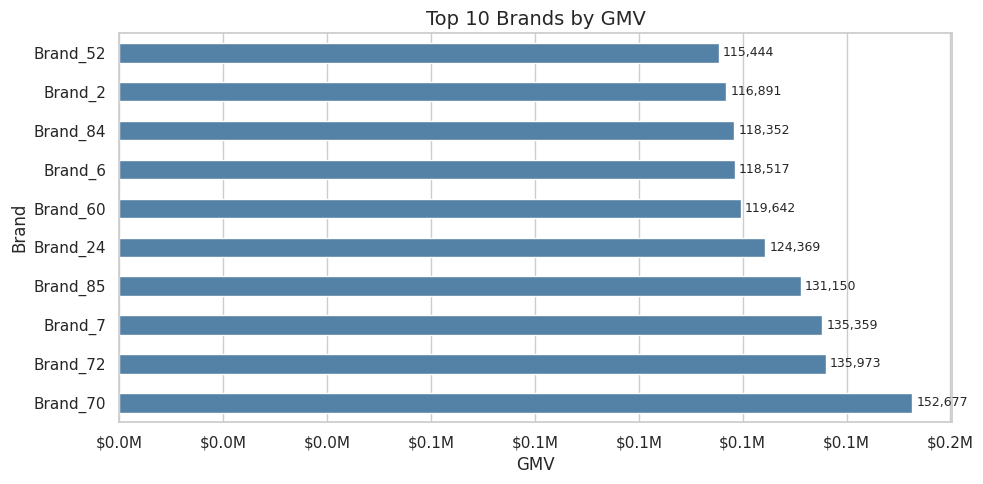

In [23]:
# Visualization: Top 10 Brands by GMV
top_brands_gmv = (
    brand_sales
    .head(10)
    .sort_values(
        'total_gmv',
        ascending = True
    )
)

plt.figure(figsize = (10, 5))

ax = sns.barplot(
    data = top_brands_gmv,
    x = 'total_gmv',
    y = 'brand',
    color = 'steelblue',
    width = 0.5
)

plt.title('Top 10 Brands by GMV', fontsize = 14)
plt.xlabel('GMV')
plt.ylabel('Brand')

# Format the x-axis in millions of dollars
ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'${x / 1e6:.1f}M')
)

ax.bar_label(
    ax.containers[0],
    fmt = lambda x: f'{x:,.0f}',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### Brand Revenue Concentration

In [24]:
# Calculate cumulative GMV share across brands
brand_concentration = brand_sales.copy()
brand_concentration['cumulative_gmv_share_%'] = (
    brand_concentration['gmv_share_%']
    .cumsum()
)

# Calculate the GMV contribution of the top 10 brands
top_10_gmv_share = (
    brand_sales
    .head(10)['gmv_share_%']
    .sum()
)

print(
    f"Top 10 brands account for"
    f"{top_10_gmv_share: .2f}% of total GMV."
)

Top 10 brands account for 14.70% of total GMV.


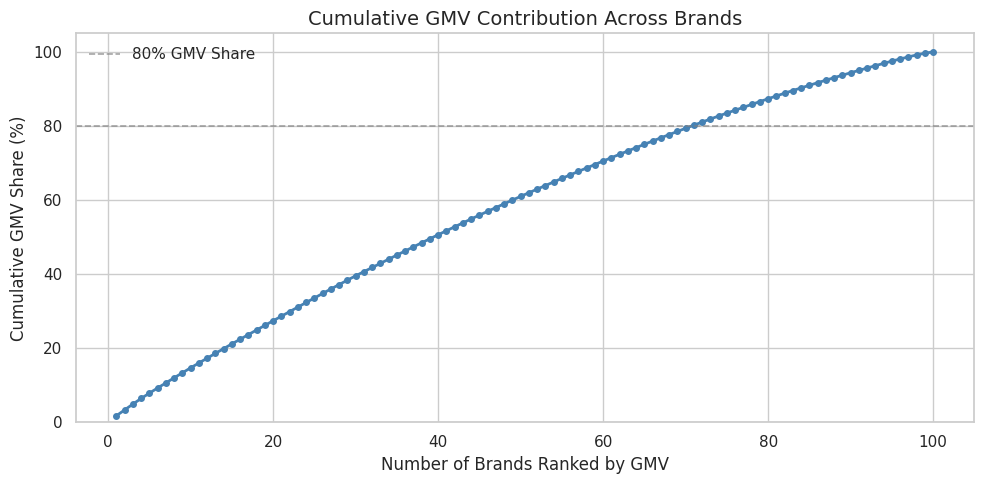

In [25]:
# Create a cumulative GMV share curve
plt.figure(figsize = (10, 5))

ax = plt.gca()

ax.plot(
    range(1, len(brand_concentration) + 1),
    brand_concentration['cumulative_gmv_share_%'],
    color = 'steelblue',
    marker = 'o',
    markersize = 4,
    linewidth = 2
)

# Add the 80% reference line
ax.axhline(
    y = 80,
    color = 'gray',
    linestyle = '--',
    linewidth = 1.2,
    alpha = 0.7,
    label = '80% GMV Share'
)

plt.title(
    'Cumulative GMV Contribution Across Brands',
    fontsize = 14
)
plt.xlabel('Number of Brands Ranked by GMV')
plt.ylabel('Cumulative GMV Share (%)')

# Set the y-axis range
ax.set_ylim(0, 105)

# Display the reference line in the legend
ax.legend(frameon = False)

plt.tight_layout()
plt.show()

### Average Transaction Value by Brand

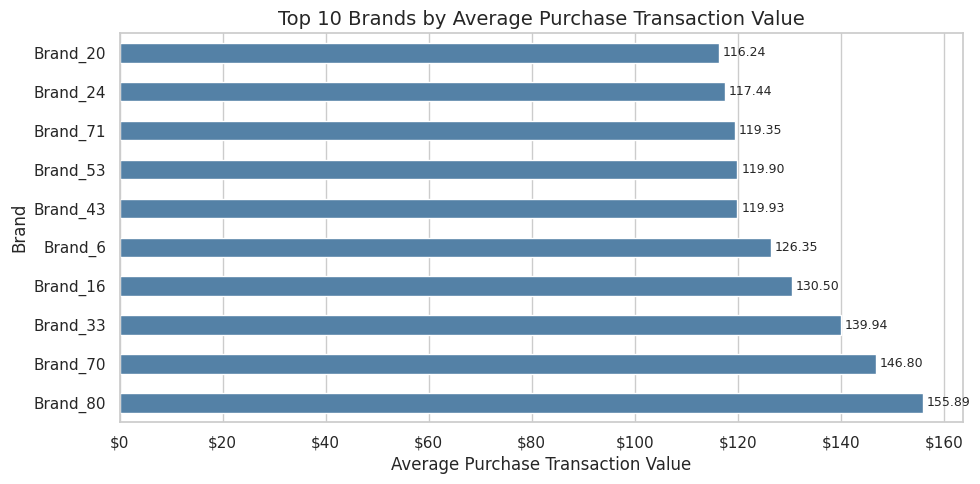

In [26]:
# Select the top 10 brands by average transaction value
top_brands_aov = (
    brand_sales
    .sort_values(
        'avg_purchase_transaction_value',
        ascending = False
    )
    .head(10)
    .sort_values(
        'avg_purchase_transaction_value',
        ascending = True
    )
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data = top_brands_aov,
    x = 'avg_purchase_transaction_value',
    y = 'brand',
    color = 'steelblue',
    width = 0.5
)

plt.title(
    'Top 10 Brands by Average Purchase Transaction Value',
    fontsize = 14
)
plt.xlabel('Average Purchase Transaction Value')
plt.ylabel('Brand')

# Format the x-axis with dollar signs and thousands separators
ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter('${x:,.0f}')
)

ax.bar_label(
    ax.containers[0],
    fmt = lambda x: f'{x:,.2f}',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### Brand Refund Performance

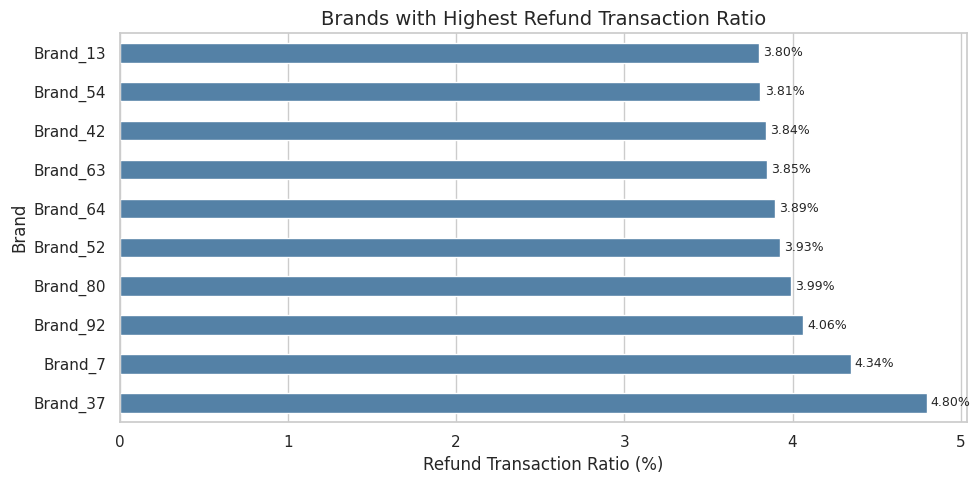

In [27]:
# Select brands with sufficient transaction volume
brand_refund = brand_sales[
    brand_sales['purchase_transactions'] >= 100
].copy()

# Select the top 10 brands by refund transaction ratio
top_refund_brands = (
    brand_refund.sort_values(
        'refund_transaction_ratio_%',
        ascending = False
    ).head(10)
    .sort_values(
        'refund_transaction_ratio_%',
        ascending = True
    )
)

plt.figure(figsize = (10, 5))

ax = sns.barplot(
    data = top_refund_brands,
    x = 'refund_transaction_ratio_%',
    y = 'brand',
    color = 'steelblue',
    width = 0.5
)

plt.title(
    'Brands with Highest Refund Transaction Ratio',
    fontsize = 14
)
plt.xlabel('Refund Transaction Ratio (%)')
plt.ylabel('Brand')

ax.bar_label(
    ax.containers[0],
    fmt = '%.2f%%',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### Brand-Level Product Conversion

In [28]:
# Keep only view and purchase events for brand-level conversion analysis
brand_funnel_data = event_prod[
    event_prod['event_type'].isin(
        ['view', 'purchase']
    )
].copy()

brand_conversion = (
    brand_funnel_data.groupby(
        ['brand', 'event_type']
    )['customer_id']
    .nunique().unstack(
        fill_value = 0
    ).reset_index()
)

# Make sure both view and purchase columns exist
for col in ['view', 'purchase']:
    if col not in brand_conversion.columns:
        brand_conversion[col] = 0

brand_conversion['conversion_rate_%'] = (
    brand_conversion['purchase'] / 
    brand_conversion['view'] * 
    100
).round(2)

brand_conversion_filtered = brand_conversion[
    brand_conversion['view'] >= 100
].copy()

# Display the top 15 brands by conversion rate
brand_conversion_top15 = (
    brand_conversion_filtered
    .sort_values(
        'conversion_rate_%',
        ascending = False
    )
    .head(15)
)

display(
    brand_conversion_top15.style.format({
        'view': '{:,.0f}',
        'purchase': '{:,.0f}',
        'conversion_rate_%': '{:.2f}%'
    }, na_rep = '—')
)

event_type,brand,purchase,view,conversion_rate_%
36,Brand_41,869,"8,398",10.35%
22,Brand_29,879,"8,865",9.92%
68,Brand_70,"1,069","10,772",9.92%
24,Brand_30,588,"5,949",9.88%
49,Brand_53,642,"6,503",9.87%
70,Brand_72,"1,394","14,134",9.86%
78,Brand_8,"1,284","13,024",9.86%
81,Brand_82,"1,280","12,993",9.85%
48,Brand_52,"1,239","12,573",9.85%
1,Brand_10,"1,114","11,403",9.77%


### Brand Conversion Visualization

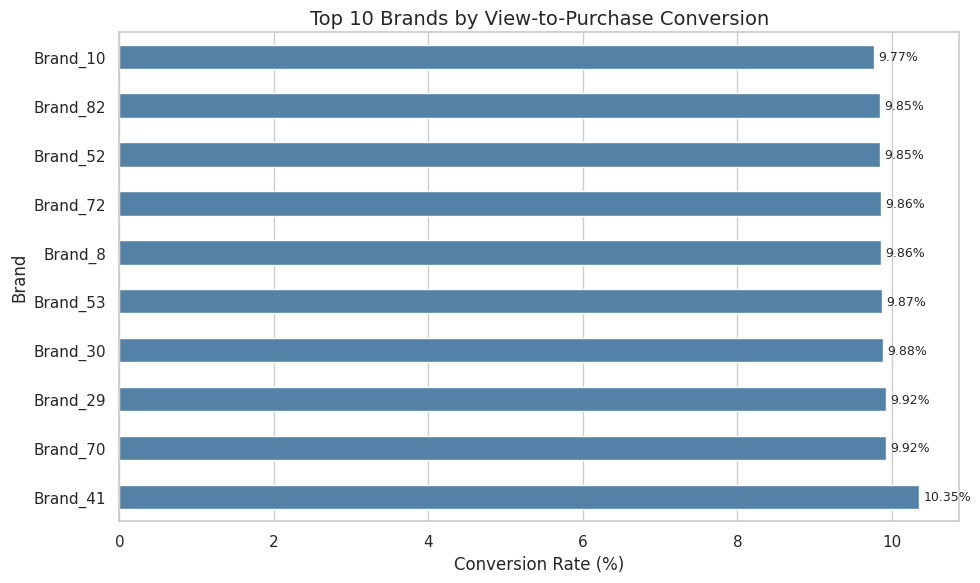

In [29]:
# Select the top 10 brands by conversion rate
top_conversion_brands = (
    brand_conversion_filtered.sort_values(
        'conversion_rate_%',
        ascending = False
    )
    .head(10).sort_values(
        'conversion_rate_%',
        ascending = True
    )
)

plt.figure(figsize = (10, 6))
ax = sns.barplot(
    data = top_conversion_brands,
    x = 'conversion_rate_%',
    y = 'brand',
    color = 'steelblue',
    width = 0.5
)

plt.title(
    'Top 10 Brands by View-to-Purchase Conversion',
    fontsize = 14
)
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Brand')

ax.bar_label(
    ax.containers[0],
    fmt = '%.2f%%',
    fontsize = 9,
    padding = 3
)

plt.tight_layout()
plt.show()

### 1.3.2 Brand Performance Matrix

The brand performance matrix combines GMV and view-to-purchase conversion rate to identify brands with different levels of scale and efficiency.

This framework highlights brands with strong performance, conversion opportunities, or potential for additional growth.

In [30]:
# Combine sales and conversion metrics at the brand level
brand_analysis = brand_sales.merge(
    brand_conversion[
        ['brand', 'view', 'purchase', 'conversion_rate_%']
    ],
    on = 'brand',
    how = 'left'
)

brand_analysis = brand_analysis.rename(
    columns={
        'view': 'unique_viewers',
        'purchase': 'unique_purchasers'
    }
)

# Remove brands without conversion data
brand_analysis = brand_analysis.dropna(
    subset = ['conversion_rate_%']
)

brand_gmv_threshold = (
    brand_analysis['total_gmv'].median()
)

brand_conversion_threshold = (
    brand_analysis['conversion_rate_%'].median()
)

In [31]:
# Classify brands based on GMV and conversion performance
def classify_brand(row):
    
    high_gmv = (
        row['total_gmv'] >= brand_gmv_threshold
    )
    
    high_conversion = (
        row['conversion_rate_%'] >= brand_conversion_threshold
    )
    
    if high_gmv and high_conversion:
        return 'High GMV / High Conversion'
    
    elif high_gmv and not high_conversion:
        return 'High GMV / Low Conversion'
    
    elif not high_gmv and high_conversion:
        return 'Low GMV / High Conversion'
    
    else:
        return 'Low GMV / Low Conversion'


# Apply the performance classification
brand_analysis['performance_segment'] = (
    brand_analysis.apply(
        classify_brand,
        axis = 1
    )
)

# Display the classified brands
brand_analysis[
    [
        'brand',
        'total_gmv',
        'gmv_share_%',
        'conversion_rate_%',
        'refund_transaction_ratio_%',
        'performance_segment'
    ]
].sort_values(
    'total_gmv',
    ascending = False
).head(20).style.format({
    'total_gmv': '{:,.2f}',
    'gmv_share_%': '{:.2f}%',
    'conversion_rate_%': '{:.2f}%',
    'refund_transaction_ratio_%': '{:.2f}%'
})

,brand,total_gmv,gmv_share_%,conversion_rate_%,refund_transaction_ratio_%,performance_segment
0,Brand_70,"152,677.08",1.77%,9.92%,3.37%,High GMV / High Conversion
1,Brand_72,"135,972.57",1.58%,9.86%,2.79%,High GMV / High Conversion
2,Brand_7,"135,359.20",1.57%,9.73%,4.34%,High GMV / High Conversion
3,Brand_85,"131,149.61",1.52%,9.75%,3.21%,High GMV / High Conversion
4,Brand_24,"124,368.99",1.44%,9.49%,2.27%,High GMV / High Conversion
5,Brand_60,"119,642.02",1.39%,9.29%,3.40%,High GMV / High Conversion
6,Brand_6,"118,517.10",1.37%,9.13%,2.03%,High GMV / Low Conversion
7,Brand_84,"118,351.99",1.37%,9.59%,3.10%,High GMV / High Conversion
8,Brand_2,"116,890.94",1.35%,9.00%,3.19%,High GMV / Low Conversion
9,Brand_52,"115,443.98",1.34%,9.85%,3.93%,High GMV / High Conversion


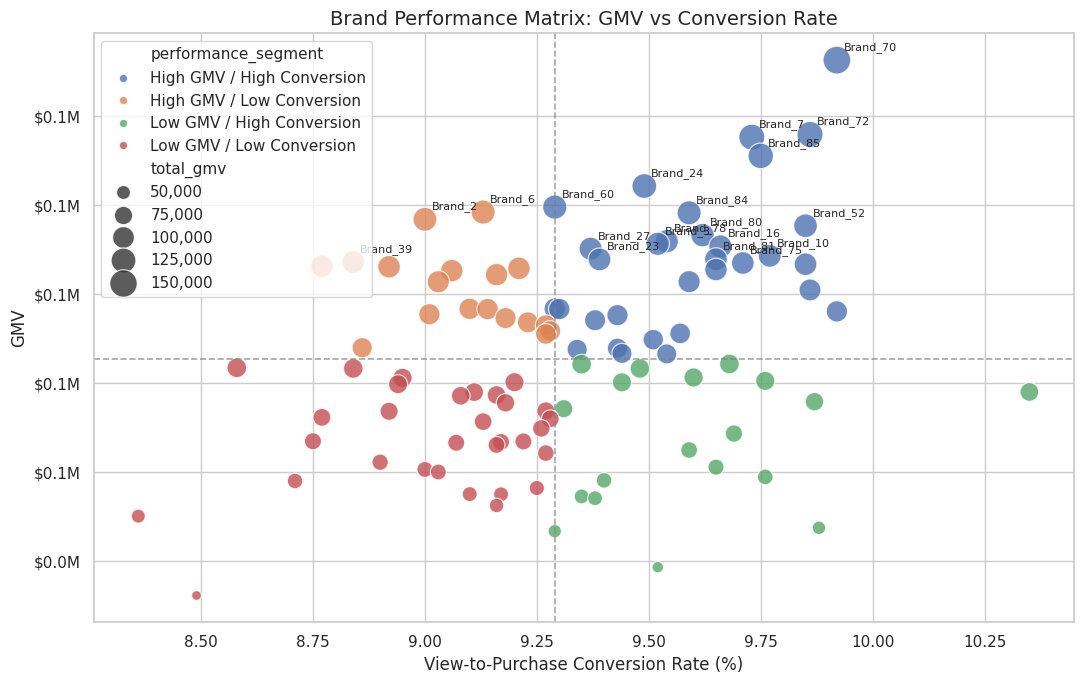

In [32]:
# Create the brand performance matrix
plt.figure(figsize = (11, 7))

ax = sns.scatterplot(
    data = brand_analysis,
    x = 'conversion_rate_%',
    y = 'total_gmv',
    size = 'total_gmv',
    sizes = (50, 400),
    hue = 'performance_segment',
    alpha = 0.8
)

# Format the bubble-size legend with thousands separators
legend = ax.get_legend()

for text in legend.get_texts():
    try:
        value = float(text.get_text())
        text.set_text(f'{value:,.0f}')
    except ValueError:
        pass

# Label only the top 15 brands by GMV to reduce clutter
top_brands = brand_analysis.nlargest(20, 'total_gmv')

# Add brand labels
for _, row in top_brands.iterrows():    
    ax.annotate(
        row['brand'],
        (
            row['conversion_rate_%'],
            row['total_gmv']
        ),
        xytext = (5, 5),
        textcoords = 'offset points',
        fontsize = 8,
        ha = 'left',
        va = 'bottom'
    )

# Add median reference lines
ax.axvline(
    brand_conversion_threshold,
    color = 'gray',
    linestyle = '--',
    linewidth = 1.2,
    alpha = 0.7
)

ax.axhline(
    brand_gmv_threshold,
    color = 'gray',
    linestyle = '--',
    linewidth = 1.2,
    alpha = 0.7
)

# Format the y-axis in millions of dollars
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'${x / 1e6:.1f}M')
)

plt.title(
    'Brand Performance Matrix: GMV vs Conversion Rate',
    fontsize = 14
)
plt.xlabel('View-to-Purchase Conversion Rate (%)')
plt.ylabel('GMV')

plt.tight_layout()
plt.show()

In [33]:
# Summary Tabel
brand_summary = brand_analysis[
    [
        'brand',
        'total_gmv',
        'gmv_share_%',
        'purchase_transactions',
        'avg_purchase_transaction_value',
        'avg_price',
        'conversion_rate_%',
        'refund_transaction_ratio_%',
        'performance_segment'
    ]
].sort_values(
    'total_gmv',
    ascending = False
)

brand_summary.head(20).style.format({
    'total_gmv': '${:,.2f}',
    'gmv_share_%': '{:.2f}%',
    'purchase_transactions': '{:,.0f}',
    'avg_purchase_transaction_value': '${:,.2f}',
    'avg_price': '${:,.2f}',
    'conversion_rate_%': '{:.2f}%',
    'refund_transaction_ratio_%': '{:.2f}%'
})

,brand,total_gmv,gmv_share_%,purchase_transactions,avg_purchase_transaction_value,avg_price,conversion_rate_%,refund_transaction_ratio_%,performance_segment
0,Brand_70,"$152,677.08",1.77%,"1,040",$146.80,$110.47,9.92%,3.37%,High GMV / High Conversion
1,Brand_72,"$135,972.57",1.58%,"1,363",$99.76,$76.27,9.86%,2.79%,High GMV / High Conversion
2,Brand_7,"$135,359.20",1.57%,"1,450",$93.35,$68.68,9.73%,4.34%,High GMV / High Conversion
3,Brand_85,"$131,149.61",1.52%,"1,154",$113.65,$88.95,9.75%,3.21%,High GMV / High Conversion
4,Brand_24,"$124,368.99",1.44%,"1,059",$117.44,$85.45,9.49%,2.27%,High GMV / High Conversion
5,Brand_60,"$119,642.02",1.39%,"1,148",$104.22,$81.57,9.29%,3.40%,High GMV / High Conversion
6,Brand_6,"$118,517.10",1.37%,938,$126.35,$94.93,9.13%,2.03%,High GMV / Low Conversion
7,Brand_84,"$118,351.99",1.37%,"1,193",$99.21,$77.41,9.59%,3.10%,High GMV / High Conversion
8,Brand_2,"$116,890.94",1.35%,"1,036",$112.83,$85.49,9.00%,3.19%,High GMV / Low Conversion
9,Brand_52,"$115,443.98",1.34%,"1,197",$96.44,$71.67,9.85%,3.93%,High GMV / High Conversion


### Key Findings

- Revenue Concentration: The top 10 brands contribute approximately 14.70% of total GMV, indicating relatively low revenue concentration across the brand portfolio.
- Portfolio Diversification: Overall revenue is distributed across a large number of brands rather than being heavily dependent on a small group of brands.
- Brand Performance: The GMV-conversion matrix helps identify brands with both scale and efficiency as well as brands that may require additional traffic or conversion optimization.
- Business Implication: Product strategy should consider portfolio-level optimization rather than focusing exclusively on a small number of dominant brands.

### Business Implications

Because revenue is relatively diversified across brands, opportunities should be evaluated using both brand-level performance and broader category-level strategy.

## 1.4 Premium Product Strategy

Evaluate whether premium products generate stronger commercial performance than non-premium products.

### Key Questions

- Do premium products generate higher revenue and average transaction value?
- Do premium products achieve higher conversion?
- Are premium products associated with different refund transaction ratio?
- Is the revenue advantage of premium products driven by order volume or transaction value?

### 1.4.1 Premium vs Non-Premium Performance

In [34]:
# Aggregate transaction-level performance by product segment
premium_sales = (
    trans_prod.groupby('product_segment')
    .agg(
        total_gmv = (
            'gross_revenue',
            lambda s: s[~trans_prod.loc[s.index, 'is_refund']].sum()
        ),
        purchase_transactions = (
            'is_refund',
            lambda s: (~s).sum()
        ),
        total_units_sold = (
            'quantity',
            lambda s: s[~trans_prod.loc[s.index, 'is_refund']].sum()
        ),
        refund_transactions = ('is_refund', 'sum'),
        net_revenue = ('gross_revenue', 'sum'),        
    )
    .reset_index()
)

# Calculate net units sold separately
net_units = (
    trans_prod.assign(
        signed_quantity = trans_prod['quantity'].where(
            ~trans_prod['is_refund'],
            -trans_prod['quantity']
        )
    )
    .groupby('product_segment')['signed_quantity']
    .sum()
)

premium_sales['net_units_sold'] = (
    premium_sales['product_segment'].map(net_units)
)

# Calculate refund transaction ratio
premium_sales['refund_transaction_ratio_%'] = (
    premium_sales['refund_transactions']
    / premium_sales['purchase_transactions']
    * 100
)

# Calculate average purchase transaction value
premium_sales['avg_purchase_transaction_value'] = (
    premium_sales['total_gmv']
    / premium_sales['purchase_transactions']
)

# Calculate GMV share
premium_sales['gmv_share_%'] = (
    premium_sales['total_gmv']
    / premium_sales['total_gmv'].sum()
    * 100
)

# Calculate average base price by brand
avg_price = (
    products
    .groupby('is_premium')['base_price']
    .mean()
    .reset_index(name = 'avg_price')
)

avg_price['product_segment'] = avg_price['is_premium'].map({
    0: 'Non-Premium',
    1: 'Premium'
})

premium_sales = premium_sales.merge(
    avg_price,
    on = 'product_segment',
    how = 'left'
)

# Sort by GMV
premium_sales = premium_sales.sort_values(
    'total_gmv', ascending = False
).reset_index(drop = True)

display(
    premium_sales.style.format({
        'total_gmv': '${:,.2f}',
        'purchase_transactions': '{:,.0f}',
        'total_units_sold': '{:,.0f}',
        'refund_transactions': '{:,.0f}',
        'net_revenue': '${:,.2f}',
        'net_units_sold': '{:,.0f}',
        'refund_transaction_ratio_%': '{:.2f}%',
        'avg_purchase_transaction_value': '${:,.2f}',
        'gmv_share_%': '{:.2f}%',
        'avg_price': '${:,.2f}'
    })
)

,product_segment,total_gmv,purchase_transactions,total_units_sold,refund_transactions,net_revenue,net_units_sold,refund_transaction_ratio_%,avg_purchase_transaction_value,gmv_share_%,is_premium,avg_price
0,Premium,"$6,650,011.96","45,126","62,283","1,385","$6,451,614.45","60,371",3.07%,$147.37,77.05%,1,$111.13
1,Non-Premium,"$1,980,257.35","44,848","62,005","1,319","$1,922,351.91","60,157",2.94%,$44.15,22.95%,0,$33.20


In [35]:
# Premium vs Non-Premium Conversion
premium_funnel = event_prod[
    event_prod['event_type'].isin(['view', 'purchase'])
].copy()

# Count unique customers at each stage
premium_conversion = (
    premium_funnel.groupby(
        ['product_segment', 'event_type'])['customer_id']
    .nunique().unstack(fill_value = 0).reset_index()
)

for col in ['view', 'purchase']:
    if col not in premium_conversion.columns:
        premium_conversion[col] = 0

premium_conversion['conversion_rate_%'] = (
    premium_conversion['purchase'] / 
    premium_conversion['view'] * 100
)

display(
    premium_conversion.style.format({
        'view': '{:,.0f}',
        'purchase': '{:,.0f}',
        'conversion_rate_%': '{:.2f}%'
    }, na_rep='—')
)

event_type,product_segment,purchase,view,conversion_rate_%
0,Non-Premium,"36,889","99,443",37.10%
1,Premium,"37,039","99,456",37.24%


In [36]:
# Combine transaction metrics with conversion metrics
premium_summary = premium_sales.merge(
    premium_conversion[
        ['product_segment', 'conversion_rate_%']
    ],
    on = 'product_segment',
    how = 'left'
)

premium_summary = premium_summary[
    [
        'product_segment',
        'total_gmv',
        'gmv_share_%',
        'purchase_transactions',
        'total_units_sold',
        'avg_purchase_transaction_value',
        'avg_price',
        'conversion_rate_%',
        'refund_transaction_ratio_%'
    ]
]

# Format values for display
premium_summary.style.format({
    'total_gmv': '${:,.2f}',
    'gmv_share_%': '{:.2f}%',
    'purchase_transactions': '{:,.0f}',
    'total_units_sold': '{:,.0f}',
    'avg_purchase_transaction_value': '${:,.2f}',
    'avg_price': '${:,.2f}',
    'conversion_rate_%': '{:.2f}%',
    'refund_transaction_ratio_%': '{:.2f}%'
})

,product_segment,total_gmv,gmv_share_%,purchase_transactions,total_units_sold,avg_purchase_transaction_value,avg_price,conversion_rate_%,refund_transaction_ratio_%
0,Premium,"$6,650,011.96",77.05%,"45,126","62,283",$147.37,$111.13,37.24%,3.07%
1,Non-Premium,"$1,980,257.35",22.95%,"44,848","62,005",$44.15,$33.20,37.10%,2.94%


In [37]:
# Compare key business metrics between Premium and Non-Premium products
comparison_metrics = [
    'total_gmv',
    'purchase_transactions',
    'avg_purchase_transaction_value',
    'conversion_rate_%',
    'refund_transaction_ratio_%'
]

premium_plot = premium_summary.set_index('product_segment').loc[
    ['Premium', 'Non-Premium'],
    comparison_metrics
]

premium_plot.style.format({
    'total_gmv': '${:,.2f}',
    'purchase_transactions': '{:,.0f}',
    'avg_purchase_transaction_value': '${:,.2f}',
    'conversion_rate_%': '{:.2f}%',
    'refund_transaction_ratio_%': '{:.2f}%'
})

,total_gmv,purchase_transactions,avg_purchase_transaction_value,conversion_rate_%,refund_transaction_ratio_%
product_segment,,,,,
Premium,"$6,650,011.96","45,126",$147.37,37.24%,3.07%
Non-Premium,"$1,980,257.35","44,848",$44.15,37.10%,2.94%


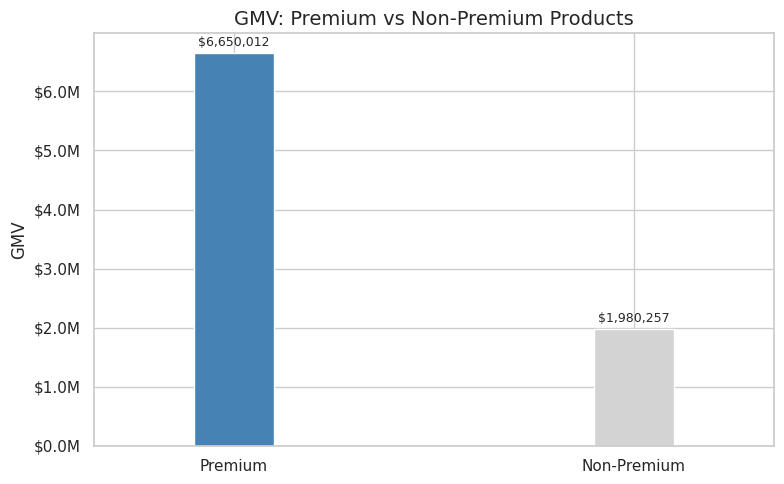

In [38]:
# Visualization of GMV
fig, ax = plt.subplots(figsize = (8, 5))

premium_plot.plot(
    y = 'total_gmv',
    kind = 'bar',
    ax = ax,
    legend = False,
    width = 0.2,
    color = ['steelblue', 'lightgray']
)

# Add value labels on top of each bar
ax.bar_label(
    ax.containers[0],
    fmt = lambda x: f'${x:,.0f}',
    fontsize = 9,
    padding = 3
)

# Format the y-axis in millions of dollars
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'${x / 1e6:.1f}M')
)

plt.title('GMV: Premium vs Non-Premium Products', fontsize = 14)
plt.xlabel('')
plt.ylabel('GMV')
plt.xticks(rotation = 0)

plt.tight_layout()
plt.show()

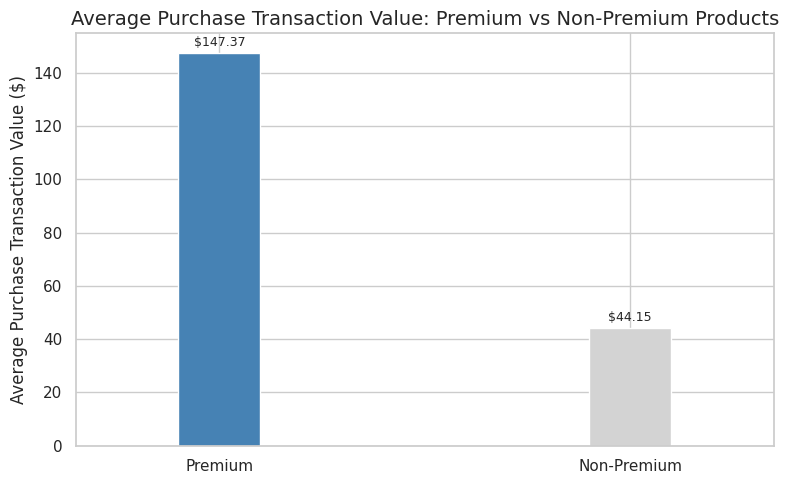

In [39]:
# Visualization of average purchase transaction value
fig, ax = plt.subplots(figsize = (8, 5))

premium_plot.plot(
    y = 'avg_purchase_transaction_value',
    kind = 'bar',
    ax = ax,
    legend = False,
    width = 0.2,
    color = ['steelblue', 'lightgray']
)

# Add value labels on top of each bar
ax.bar_label(
    ax.containers[0],
    fmt = lambda x: f'${x:,.2f}',
    fontsize = 9,
    padding = 3
)

plt.title(
    'Average Purchase Transaction Value: Premium vs Non-Premium Products',
    fontsize=14
)
plt.xlabel('')
plt.ylabel('Average Purchase Transaction Value ($)')
plt.xticks(rotation = 0)

plt.tight_layout()
plt.show()

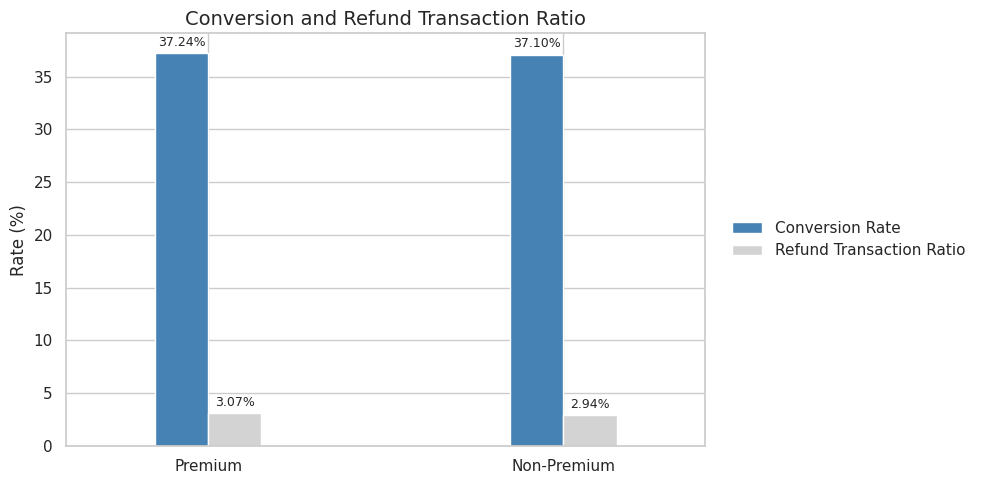

In [40]:
# Conversion & refund comparison
# Create a compact comparison for conversion and refund transaction ratio
rate_comparison = premium_plot[
    ['conversion_rate_%', 'refund_transaction_ratio_%']
]

fig, ax = plt.subplots(figsize=(10, 5))

rate_comparison.plot(
    kind = 'bar',
    ax = ax,
    width = 0.3,
    color=['steelblue', 'lightgray']
)

# Add percentage labels on top of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt = lambda x: f'{x:.2f}%',
        fontsize = 9,
        padding = 3
    )
    
plt.title('Conversion and Refund Transaction Ratio', fontsize = 14)
plt.xlabel('')
plt.ylabel('Rate (%)')
plt.xticks(rotation = 0)

plt.legend(
    ['Conversion Rate', 'Refund Transaction Ratio'],
    loc = 'center left',
    bbox_to_anchor = (1.02, 0.5),
    frameon = False
)

plt.tight_layout()
plt.show()


### Key Findings

- Revenue Contribution: Premium products generated approximately 77.05% of total GMV despite having a similar number of orders to non-premium products.
- Transaction Value: Premium products had a substantially higher average purchase transaction value of approximately $147.37, compared with $44.15 for non-premium products.
- Conversion: Premium and non-premium products showed very similar conversion rates, suggesting that the revenue advantage of premium products is primarily associated with higher transaction value rather than substantially higher conversion.
- Refunds: Refund transaction ratio were also similar between the two product tiers, indicating no major refund-transaction-ratio difference in this dataset.

### Business Implications

Premium products appear to be an important revenue driver. Continued investment in premium products should focus on maintaining customer experience and monitoring refund behavior while preserving their higher transaction value.

## Module Summary

### Key Findings

- Electronics is the largest revenue-driving category and contributes a substantial share of total GMV.
- The largest product funnel bottleneck occurs between add-to-cart and purchase.
- Brand revenue is relatively diversified, with the top 10 brands contributing only a modest share of total GMV.
- Premium products generate substantially higher transaction value while maintaining similar conversion and refund rates to non-premium products.

These findings provide the foundation for evaluating how pricing and discount strategies affect commercial performance in the next module.

# Module 2: Pricing & Discount Effectiveness

This module evaluates how discount usage is associated with transaction value, repeat purchase behavior, and historical customer value.

### Key Questions

- Do discounted transactions generate higher or lower revenue per transaction?
- How does transaction value change as discount levels increase?
- Do first-order discounts relate to repeat purchase behavior?
- Which customer groups show higher historical value based on discount usage?
- Does discount effectiveness differ across product categories?

## 2.1 Revenue per Transaction by Discount

Compare average revenue per transaction between discounted and non-discounted transactions.

The analysis then examines whether increasing discount levels are associated with changes in average transaction value. Refund transactions are not included in this analysis.

In [41]:
# Exclude refund records
purchase_data = transactions.loc[
    ~transactions['is_refund']
].copy()

# Create a flag for discount usage
purchase_data['has_discount'] = (
    purchase_data['discount_applied'] > 0
).astype(int)

# Calculate revenue metrics by discount status
discount_revenue = purchase_data.groupby('has_discount').agg(
    transaction_count = ('transaction_id', 'nunique'),
    total_revenue = ('gross_revenue', 'sum'),
    avg_revenue_per_transaction = ('gross_revenue', 'mean'),
    median_revenue_per_transaction = ('gross_revenue', 'median')
).reset_index()

discount_revenue['discount_type'] = (
    discount_revenue['has_discount'].map({
        0: 'No Discount',
        1: 'Discount Applied'
    })
)

display(
    discount_revenue[
        [
            'discount_type',
            'transaction_count',
            'total_revenue',
            'avg_revenue_per_transaction',
            'median_revenue_per_transaction'
        ]
    ].style.format({
        'transaction_count': '{:,.0f}',
        'total_revenue': '${:,.2f}',
        'avg_revenue_per_transaction': '${:,.2f}',
        'median_revenue_per_transaction': '${:,.2f}'
    })
)

,discount_type,transaction_count,total_revenue,avg_revenue_per_transaction,median_revenue_per_transaction
0,No Discount,"54,079","$5,387,266.22",$99.62,$73.34
1,Discount Applied,"35,895","$3,243,003.09",$90.35,$66.01


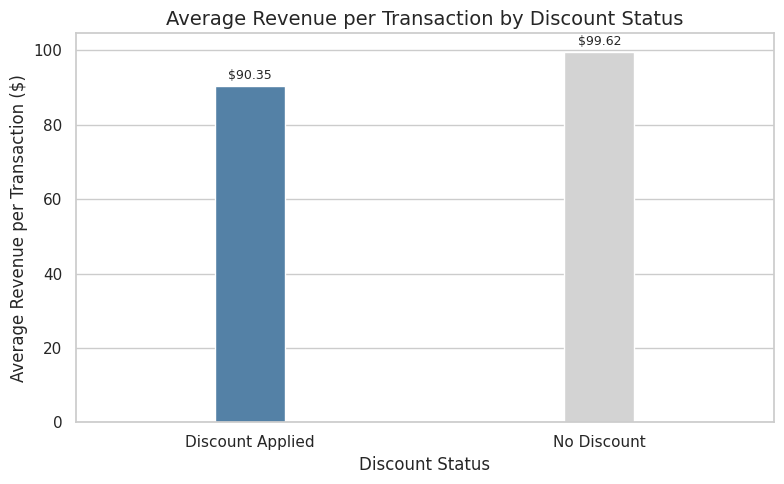

In [42]:
# Visualization: average revenue per transaction
# Visualize average revenue per transaction by discount status.
palette = {
    'Discount Applied': 'steelblue',
    'No Discount': 'lightgray'
}

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data = discount_revenue, 
    x = 'discount_type', 
    y = 'avg_revenue_per_transaction',
    hue = 'discount_type',
    order = ['Discount Applied', 'No Discount'],
    palette = palette,
    legend = False,
    errorbar = None,
    width = 0.2,
    ax = ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt = lambda x: f'${x:,.2f}',
        fontsize = 9,
        padding = 3
    )

plt.title(
    'Average Revenue per Transaction by Discount Status',
    fontsize = 14
)
plt.xlabel('Discount Status')
plt.ylabel('Average Revenue per Transaction ($)')

plt.tight_layout()
plt.show()

### Average Revenue per Transaction by Discount Level
Evaluate whether higher discount levels are associated with changes in average revenue per transaction.

Because discount levels are observational rather than randomly assigned, the results describe associations rather than causal effects.

In [43]:
# Analyze revenue by discount level
discount_level = (
    purchase_data[purchase_data['discount_applied'] > 0]
    .groupby('discount_applied')
    .agg(
        transaction_count = ('transaction_id', 'nunique'),
        total_revenue = ('gross_revenue', 'sum'),
        avg_revenue_per_transaction = ('gross_revenue', 'mean'),
        avg_items_per_transaction = ('quantity', 'mean')
    )
    .reset_index()
)

display(
    discount_level.style.format({
        'discount_applied': '{:.0%}',
        'transaction_count': '{:,.0f}',
        'total_revenue': '${:,.2f}',
        'avg_revenue_per_transaction': '${:,.2f}',
        'avg_items_per_transaction': '{:.2f}'
    })
)

,discount_applied,transaction_count,total_revenue,avg_revenue_per_transaction,avg_items_per_transaction
0,5%,"13,512","$1,298,457.58",$96.10,1.39
1,10%,"10,760","$976,054.63",$90.71,1.39
2,15%,"7,255","$621,919.38",$85.72,1.38
3,20%,"4,368","$346,571.50",$79.34,1.38


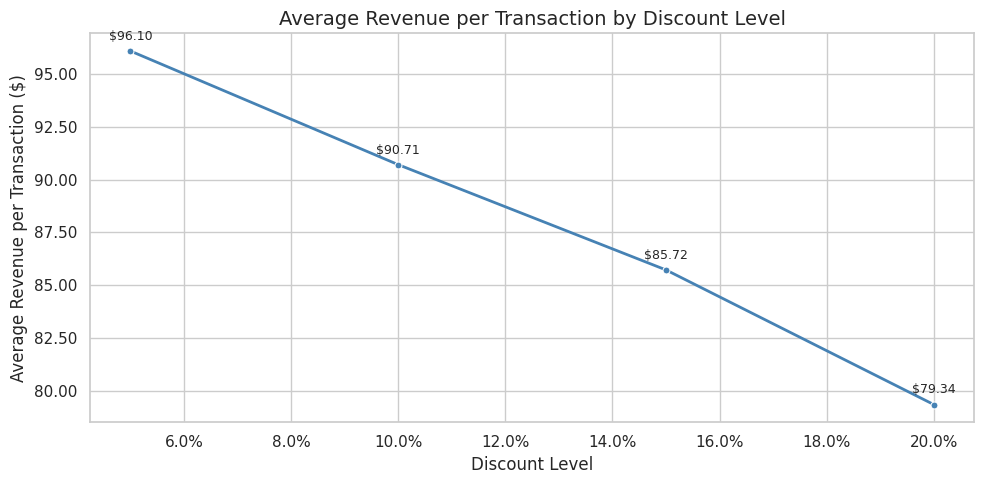

In [44]:
# Visualization: Average Revenue per Transaction by Discount Level
fig, ax = plt.subplots(figsize = (10, 5))

sns.lineplot(
    data = discount_level.sort_values('discount_applied'),
    x = 'discount_applied',
    y = 'avg_revenue_per_transaction',
    marker = 'o',
    markersize = 5,
    linewidth = 2,
    color = 'steelblue',
    ax = ax
)

# Add data labels
for x, y in zip(
    discount_level.sort_values('discount_applied')['discount_applied'],
    discount_level.sort_values('discount_applied')['avg_revenue_per_transaction']
):
    ax.annotate(
        f'${y:,.2f}',
        (x, y),
        textcoords = 'offset points',
        xytext = (0, 8),
        ha = 'center',
        fontsize = 9
    )

plt.title('Average Revenue per Transaction by Discount Level', fontsize = 14)
plt.xlabel('Discount Level')
plt.ylabel('Average Revenue per Transaction ($)')

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel('Discount Level')

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.2f}')
)

plt.tight_layout()
plt.show()

## 2.2 Repeat Purchase by First-Order Discount

Evaluate whether customers who receive a discount on their first order show different repeat-purchase behavior from customers whose first order was not discounted.

A repeat customer is defined as a customer with at least two recorded transactions.

In [45]:
# Sort purchase transactions by customer and timestamp
purchase_data = purchase_data.sort_values(
    ['customer_id', 'timestamp', 'transaction_id']
)

# Identify each customer's first purchase
first_purchase = (
    purchase_data
    .drop_duplicates('customer_id', keep = 'first')
    [['customer_id', 'has_discount']]
    .rename(columns = {
        'has_discount': 'first_purchase_discount'
    })
    .copy()
)

# Count purchase transactions per customer
customer_purchase_count = (
    purchase_data.groupby('customer_id')
    .agg(
        total_transactions = ('transaction_id', 'nunique')
    )
    .reset_index()
)

# Merge first-purchase discount status with purchase frequency
cust_repeat = customer_purchase_count.merge(
    first_purchase,
    on = 'customer_id',
    how = 'left'
)

# Define repeat customers as customers with at least 2 purchases
cust_repeat['is_repeat'] = (
    cust_repeat['total_transactions'] >= 2
).astype(int)

# Calculate repeat purchase rate by first-purchase discount
repeat_by_discount = (
    cust_repeat.groupby('first_purchase_discount')
    .agg(
        customer_count = ('customer_id', 'nunique'),
        repeat_customer_count = ('is_repeat', 'sum'),
        repeat_purchase_rate = ('is_repeat', lambda x: x.mean() * 100)
    )
    .reset_index()
)

# Add readable group labels
repeat_by_discount['cohort_type'] = (
    repeat_by_discount['first_purchase_discount']
    .map({
        0: 'First Purchase: No Discount',
        1: 'First Purchase: Discount'
    })
)

display(
    repeat_by_discount[
        [
            'cohort_type',
            'customer_count',
            'repeat_customer_count',
            'repeat_purchase_rate'
        ]
    ].style.format({
        'customer_count': '{:,.0f}',
        'repeat_customer_count': '{:,.0f}',
        'repeat_purchase_rate': '{:.2f}%'
    })
)

,cohort_type,customer_count,repeat_customer_count,repeat_purchase_rate
0,First Purchase: No Discount,"35,400","13,702",38.71%
1,First Purchase: Discount,"23,587","8,916",37.80%


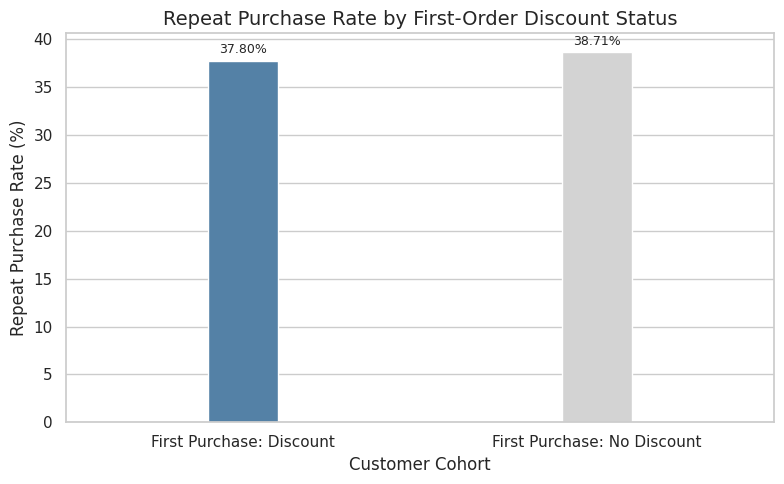

In [46]:
# Visualization: Repeat Purchase Rate
fig, ax = plt.subplots(figsize = (8, 5))

palette = {
    'First Purchase: Discount': 'steelblue',
    'First Purchase: No Discount': 'lightgray'
}

sns.barplot(
    data = repeat_by_discount, 
    x = 'cohort_type',
    y = 'repeat_purchase_rate',
    hue = 'cohort_type',
    order = [
        'First Purchase: Discount',
        'First Purchase: No Discount'
    ],
    hue_order = [
        'First Purchase: Discount',
        'First Purchase: No Discount'
    ],
    palette = palette,
    legend = False,
    errorbar = None,
    width = 0.2,
    ax = ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt = lambda x: f'{x:.2f}%',
        fontsize = 9,
        padding = 3
    )

plt.title('Repeat Purchase Rate by First-Order Discount Status', fontsize = 14)
plt.ylabel('Repeat Purchase Rate (%)')
plt.xlabel('Customer Cohort')
plt.xticks(rotation = 0)

plt.tight_layout()
plt.show()

## 2.3 Customer Value by Discount Usage

Compare historical customer revenue and transaction frequency across different levels of discount usage.

This analysis describes differences between customer groups. It does not estimate the causal effect of discounts because discount exposure was not randomly assigned.

In [47]:
# Calculate total customer-level metrics
customer_value = purchase_data.groupby('customer_id').agg(
    total_transactions = ('transaction_id', 'nunique'),
    total_revenue = ('gross_revenue', 'sum'),
    total_discount_transactions = ('has_discount', 'sum')
).reset_index()

# Calculate the proportion of transactions using discounts
customer_value['discount_transaction_ratio'] = (
    customer_value['total_discount_transactions'] / 
    customer_value['total_transactions']
)

# Calculate discount intensity segments
def discount_segment(ratio):
    if ratio == 0:
        return 'Never Discount'
    elif ratio < 0.5:
        return 'Occasional Discount'
    else:
        return 'Frequent Discount'

customer_value['discount_segment'] = (
    customer_value['discount_transaction_ratio']
    .apply(discount_segment)
)

# Summarize customer value by discount usage
value_by_discount = customer_value.groupby(
    'discount_segment'
).agg(
    customer_count = ('customer_id', 'nunique'),
    avg_transactions = ('total_transactions', 'mean'),
    avg_customer_revenue = ('total_revenue', 'mean'),
    median_customer_revenue = ('total_revenue', 'median')
).reset_index()

display(
    value_by_discount[
        [
            'discount_segment',
            'customer_count',
            'avg_transactions',
            'avg_customer_revenue',
            'median_customer_revenue'
        ]
    ].style.format({
        'customer_count': '{:,.0f}',
        'avg_transactions': '{:.2f}',
        'avg_customer_revenue': '${:,.2f}',
        'median_customer_revenue': '${:,.2f}'
    })
)

,discount_segment,customer_count,avg_transactions,avg_customer_revenue,median_customer_revenue
0,Frequent Discount,"27,387",1.59,$145.82,$105.65
1,Never Discount,"28,829",1.30,$129.75,$91.82
2,Occasional Discount,"2,771",3.29,$323.48,$276.48


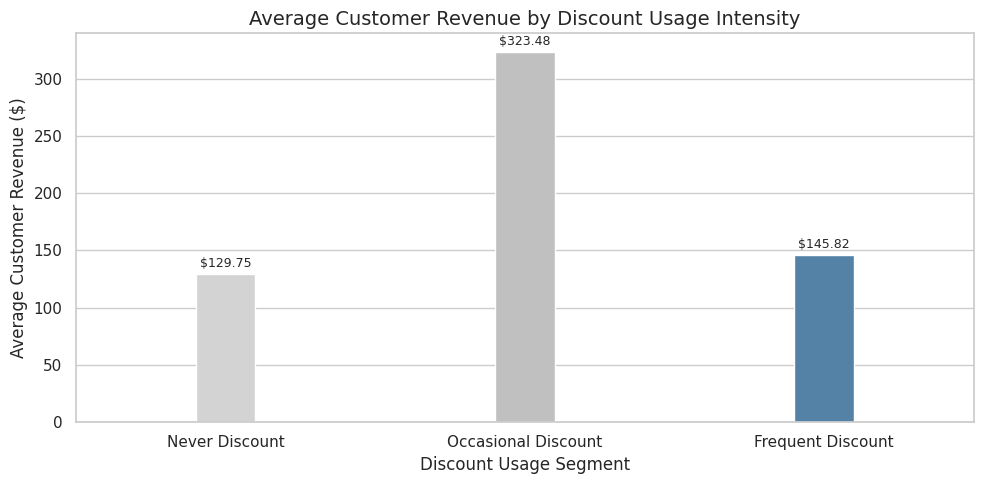

In [48]:
# Visualization: average cutomer value by discount segment
fig, ax = plt.subplots(figsize = (10, 5))

segment_order = [
    'Never Discount',
    'Occasional Discount',
    'Frequent Discount'
]

palette = {
    'Never Discount': 'lightgray',
    'Occasional Discount': 'silver',
    'Frequent Discount': 'steelblue'
}

sns.barplot(
    data = value_by_discount,
    x = 'discount_segment',
    y = 'avg_customer_revenue',
    hue = 'discount_segment',
    order = segment_order,
    hue_order = segment_order,
    palette = palette,
    legend = False,
    errorbar = None,
    width = 0.2,
    ax = ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt = lambda x: f'${x:,.2f}',
        fontsize = 9,
        padding = 3
    )
    
plt.title('Average Customer Revenue by Discount Usage Intensity', fontsize = 14)
plt.ylabel('Average Customer Revenue ($)')
plt.xlabel('Discount Usage Segment')
plt.xticks(rotation = 0)

plt.tight_layout()
plt.show()

### Key Findings

- Order Value: Average revenue per transaction decreases as discount levels increase, indicating an inverse association between discount depth and transaction value in this dataset.
- Repeat Purchase: First-purchase discount users show a repeat-purchase rate of approximately 37.80%, compared with 38.71% for customers without a first-purchase discount. The difference is small.
- Customer Value: Occasional discount users show the highest historical customer value, with substantially higher average revenue and transaction frequency than the other discount-usage groups.
- Causal Interpretation: The higher historical value of occasional-discount customers should not be interpreted as evidence that discounts increase customer value, because discount usage was not randomly assigned.

### Business Implications

Broad or deeper discounting does not appear to provide a clear repeat-purchase advantage in this dataset. Discounts may therefore be more effective when used selectively for specific customer or product segments.

## 2.4 Discount Performance by Product Category

Discount effectiveness may differ across product categories because categories have different price levels, purchase behavior, and customer demand.

### Key Questions

- Does the relationship between discount level and average revenue per transaction differ across categories?
- Which categories maintain stronger transaction value under discounting?
- Are higher discounts concentrated in particular product categories?

In [49]:
# Keep purchase transactions and exclude refunds
purchase_trans_prod = trans_prod.loc[
    ~trans_prod['is_refund']
].copy()

# Compare average revenue per transaction across discount levels and product categories.
discount_category = (
    purchase_trans_prod
    .groupby(['category', 'discount_applied'])
    .agg(
        transaction_count = ('transaction_id', 'nunique'),
        total_revenue = ('gross_revenue', 'sum')
    )
    .reset_index()
)

discount_category['avg_revenue_per_transaction'] = (
    discount_category['total_revenue']
    / discount_category['transaction_count']
)

display(
    discount_category[
        [
            'category',
            'discount_applied',
            'transaction_count',
            'total_revenue',
            'avg_revenue_per_transaction'
        ]
    ].style.format({
        'discount_applied': '{:.0%}',
        'transaction_count': '{:,.0f}',
        'total_revenue': '${:,.2f}',
        'avg_revenue_per_transaction': '${:,.2f}'
    })
)


,category,discount_applied,transaction_count,total_revenue,avg_revenue_per_transaction
0,Beauty,0%,"5,435","$242,236.13",$44.57
1,Beauty,5%,"1,309","$55,116.30",$42.11
2,Beauty,10%,"1,071","$43,061.95",$40.21
3,Beauty,15%,690,"$25,789.21",$37.38
4,Beauty,20%,433,"$15,235.46",$35.19
5,Electronics,0%,"12,220","$2,210,722.16",$180.91
6,Electronics,5%,"3,119","$536,523.25",$172.02
7,Electronics,10%,"2,469","$405,451.13",$164.22
8,Electronics,15%,"1,670","$260,629.64",$156.07
9,Electronics,20%,991,"$140,849.43",$142.13


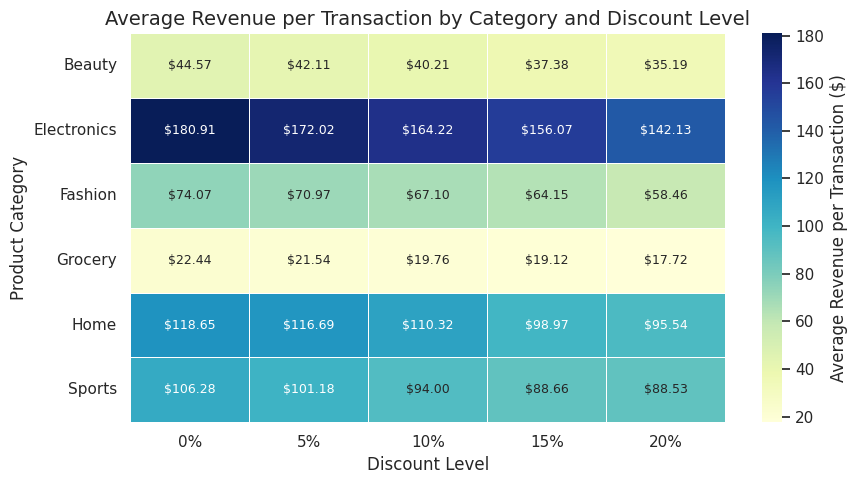

In [50]:
# Visualize average revenue per transaction by category and discount level.
pivot_aov = discount_category.pivot(
    index = 'category',
    columns = 'discount_applied',
    values = 'avg_revenue_per_transaction'
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(
    pivot_aov,
    annot = True,
    fmt = '.2f',
    cmap = 'YlGnBu',
    linewidths = 0.5,
    cbar_kws = {'label': 'Average Revenue per Transaction ($)'},
    ax = ax
)

# Add dollar signs to cell annotations
for text in ax.texts:
    text.set_text(f'${float(text.get_text()):,.2f}')
    text.set_fontsize(9)

plt.title(
    'Average Revenue per Transaction by Category and Discount Level',
    fontsize = 14
)
plt.xlabel('Discount Level')
plt.ylabel('Product Category')

ax.set_xticklabels([
    f'{float(label.get_text()):.0%}'
    for label in ax.get_xticklabels()
])

plt.tight_layout()
plt.show()

## Module Summary

### Key Findings

- Higher discount levels are associated with lower average revenue per transaction.
- First-purchase discounts show little difference in repeat-purchase rate compared with non-discounted first transactions.
- Occasional discount users have the highest historical customer value, although this relationship should not be interpreted causally.
- Discount performance may vary across product categories, suggesting that targeted discounting may be more appropriate than broad discounting.

These findings suggest that discount strategy should balance conversion objectives, transaction value, and long-term customer value rather than maximizing discount usage.

# Module 3: Future Customer Value Prediction
This module evaluates whether historical customer behavior can be used to predict revenue generated during a future 180-day period.

Unlike the historical CLV analysis in Project 1, which measures realized customer value, this module focuses on forward-looking revenue prediction.

### Business Question

> Can historical customer behavior predict whether a customer will purchase in the future and how much revenue they will generate?

### Approach

- **Historical period:** January 2021 – June 2023
- **Cutoff date:** June 30, 2023
- **Prediction window:** July 1 – December 31, 2023
- **Target:** Customer revenue generated during the 180-day prediction window

All predictive features are calculated using information available before the cutoff date to avoid data leakage.

## 3.1 One-Stage Future Revenue Prediction

### 3.1.1 Feature Engineering & Prediction Target

The one-stage model directly predicts customer revenue during the future 180-day prediction period.

Historical customer features are calculated using transactions and events observed before the cutoff date.

The prediction target is:

future_revenue = revenue generated during the 180-day prediction period

In [51]:
# Convert timestamp to datetime
transactions['timestamp'] = pd.to_datetime(transactions['timestamp'])

# Check the time range of the transaction data
min_date = transactions['timestamp'].min()
max_date = transactions['timestamp'].max()
date_range = max_date - min_date

print(f"Start date: {min_date}")
print(f"End date: {max_date}")
print(f"Time span: {date_range.days} days")
print(f"Time span: {date_range.days / 30.44:.1f} months")
print(f"Time span: {date_range.days / 365.25:.2f} years")

Start date: 2021-01-01 00:12:50
End date: 2023-12-31 22:37:32
Time span: 1094 days
Time span: 35.9 months
Time span: 3.00 years


In [52]:
# Check transaction volume by month
monthly_transactions = (
    transactions
    .set_index('timestamp')
    .resample('ME')
    .size()
)

monthly_transactions

timestamp
2021-01-31    2503
2021-02-28    2237
2021-03-31    2519
2021-04-30    2445
2021-05-31    2598
2021-06-30    2406
2021-07-31    2464
2021-08-31    2570
2021-09-30    2482
2021-10-31    2507
2021-11-30    3139
2021-12-31    3235
2022-01-31    2499
2022-02-28    2221
2022-03-31    2485
2022-04-30    2334
2022-05-31    2460
2022-06-30    2491
2022-07-31    2414
2022-08-31    2508
2022-09-30    2367
2022-10-31    2457
2022-11-30    3187
2022-12-31    3238
2023-01-31    2568
2023-02-28    2223
2023-03-31    2436
2023-04-30    2443
2023-05-31    2447
2023-06-30    2363
2023-07-31    2539
2023-08-31    2479
2023-09-30    2476
2023-10-31    2527
2023-11-30    3111
2023-12-31    3300
Freq: ME, dtype: int64

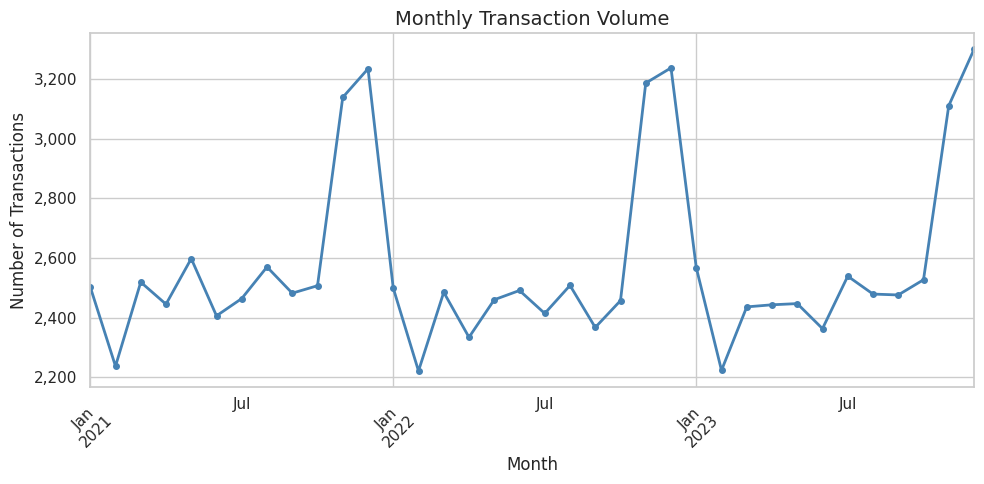

In [53]:
# Visualize monthly transaction volume
fig, ax = plt.subplots(figsize = (10, 5))

monthly_transactions.plot(
    ax = ax,
    color = 'steelblue',
    marker = 'o',
    markersize = 4,
    linewidth = 2
)

# Format y-axis as whole numbers with thousands separators
ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)

plt.title('Monthly Transaction Volume', fontsize = 14)
plt.xlabel('Month')
plt.ylabel('Number of Transactions')

plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [54]:
# Make sure timestamp is in datetime format
events['timestamp'] = pd.to_datetime(events['timestamp'])

# Define the cutoff date
cutoff_date = pd.Timestamp('2023-06-30 23:59:59')

# Define the end of the prediction window
prediction_end = pd.Timestamp('2023-12-31 23:59:59')

print(f"Cutoff date: {cutoff_date}")
print(f"Prediction period: {cutoff_date + pd.Timedelta(seconds = 1)} to {prediction_end}")
print(f"Prediction window: {(prediction_end - cutoff_date).days} days")

Cutoff date: 2023-06-30 23:59:59
Prediction period: 2023-07-01 00:00:00 to 2023-12-31 23:59:59
Prediction window: 184 days


In [55]:
# Split transactions into historical and future periods
hist_trans = transactions[
    transactions['timestamp'] <= cutoff_date
].copy()

future_trans = transactions[
    (transactions['timestamp'] > cutoff_date) &
    (transactions['timestamp'] <= prediction_end)
].copy()

print("Historical transactions:", len(hist_trans))
print("Future transactions:", len(future_trans))

print("\nHistorical period:")
print(hist_trans['timestamp'].min(), "to", hist_trans['timestamp'].max())

print("\nFuture prediction period:")
print(future_trans['timestamp'].min(), "to", future_trans['timestamp'].max())

Historical transactions: 76246
Future transactions: 16432

Historical period:
2021-01-01 00:12:50 to 2023-06-30 23:38:53

Future prediction period:
2023-07-01 00:04:09 to 2023-12-31 22:37:32


### Historical Customer Features
Historical features capture several dimensions of customer behavior:

- Purchase Recency: Time since the customer's latest historical purchase
- Purchase Frequency: Number of historical transactions
- Transaction Value: Average historical revenue per transaction
- Purchase Volume: Historical quantity purchased
- Marketing Engagement: Historical campaign exposure
- Discount Usage: Historical discount frequency
- Customer Profile: Acquisition channel and country

In [56]:
# Keep purchase records for historical behavior features
purchase_trans = hist_trans[
    hist_trans['is_refund'] == False
].copy()

# Create customer-level historical purchase features
cust_features = (
    purchase_trans
    .groupby('customer_id')
    .agg(
        last_trans_date = ('timestamp', 'max'),
        total_trans = ('transaction_id', 'nunique'),
        avg_trans_value = ('gross_revenue', 'mean'),
        total_quantity = ('quantity', 'sum')
    )
    .reset_index()
)

# Calculate recency as of the cutoff date
cust_features['recency_days'] = (
    cutoff_date - cust_features['last_trans_date']
).dt.days

# Remove the intermediate date column
cust_features = cust_features.drop(columns = 'last_trans_date')

display(
    cust_features.head().style.format({
        'total_trans': '{:,.0f}',
        'avg_trans_value': '${:,.2f}',
        'total_quantity': '{:,.0f}',
        'recency_days': '{:,.0f}'
    })
)

,customer_id,total_trans,avg_trans_value,total_quantity,recency_days
0,2,1,$60.09,1,881
1,9,1,$65.63,1,450
2,13,1,$71.90,1,576
3,14,1,$76.14,1,373
4,17,1,$97.28,1,320


In [57]:
# Add customer acquisition and geographic information
cust_features = cust_features.merge(
    customers[
        ['customer_id', 'acquisition_channel', 'country']
    ],
    on = 'customer_id',
    how = 'left'
)

display(
    cust_features.head().style.format({
        'total_trans': '{:,.0f}',
        'avg_trans_value': '${:,.2f}',
        'total_quantity': '{:,.0f}',
        'recency_days': '{:,.0f}'
    })
)

,customer_id,total_trans,avg_trans_value,total_quantity,recency_days,acquisition_channel,country
0,2,1,$60.09,1,881,Organic,IN
1,9,1,$65.63,1,450,Paid Search,BR
2,13,1,$71.90,1,576,Organic,US
3,14,1,$76.14,1,373,Paid Search,IN
4,17,1,$97.28,1,320,Organic,BR


In [58]:
# Keep only events occurring before the cutoff date
hist_events = events[
    events['timestamp'] <= cutoff_date
].copy()

# Calculate historical campaign engagement
cust_campaign = (
    hist_events.groupby('customer_id')
    .agg(
        campaign_views = ('campaign_id', 'nunique')
    )
    .reset_index()
)

# Merge campaign engagement into customer features
cust_features = cust_features.merge(
    cust_campaign,
    on = 'customer_id',
    how = 'left'
)

# Customer without campaign views are assigned 0
cust_features['campaign_views'] = (
    cust_features['campaign_views'].fillna(0)
)

display(
    cust_features.head().style.format({
        'total_trans': '{:,.0f}',
        'avg_trans_value': '${:,.2f}',
        'total_quantity': '{:,.0f}',
        'recency_days': '{:,.0f}',
        'campaign_views': '{:,.0f}'
    })
)

,customer_id,total_trans,avg_trans_value,total_quantity,recency_days,acquisition_channel,country,campaign_views
0,2,1,$60.09,1,881,Organic,IN,4
1,9,1,$65.63,1,450,Paid Search,BR,4
2,13,1,$71.90,1,576,Organic,US,10
3,14,1,$76.14,1,373,Paid Search,IN,13
4,17,1,$97.28,1,320,Organic,BR,7


In [59]:
# Discount Usage
cust_discount = (
    purchase_trans.groupby('customer_id')
    .agg(
        discount_trans = (
            'discount_applied',
            lambda x: (x > 0).sum()
        ),
        total_trans = (
            'transaction_id', 'nunique'
        )
    ).reset_index()
)

# Calculate the proportion of discounted orders
cust_discount['discount_rate'] = (
    cust_discount['discount_trans'] /
    cust_discount['total_trans']
)

cust_discount = cust_discount[
    ['customer_id', 'discount_rate']
]

cust_features = cust_features.merge(
    cust_discount,
    on = 'customer_id',
    how = 'left'
)

cust_features['discount_rate'] = (
    cust_features['discount_rate'].fillna(0)
)

display(
    cust_features.head().style.format({
        'total_trans': '{:,.0f}',
        'avg_trans_value': '${:,.2f}',
        'total_quantity': '{:,.0f}',
        'recency_days': '{:,.0f}',
        'campaign_views': '{:,.0f}',
        'discount_rate': '{:.2f}%'
    })
)

,customer_id,total_trans,avg_trans_value,total_quantity,recency_days,acquisition_channel,country,campaign_views,discount_rate
0,2,1,$60.09,1,881,Organic,IN,4,1.00%
1,9,1,$65.63,1,450,Paid Search,BR,4,1.00%
2,13,1,$71.90,1,576,Organic,US,10,0.00%
3,14,1,$76.14,1,373,Paid Search,IN,13,0.00%
4,17,1,$97.28,1,320,Organic,BR,7,1.00%


### Create Future Revenue Target
Future revenue is calculated as the sum of gross_revenue generated during the prediction period.

Negative revenue values associated with refunds are retained as valid financial adjustments.

In [60]:
# Calculate revenue generated during the future prediction period
future_revenue = (
    future_trans.groupby('customer_id')
    .agg(
        future_revenue = ('gross_revenue', 'sum')
    ).reset_index()
)

# Combine historical features with the future target
model_data = cust_features.merge(
    future_revenue,
    on = 'customer_id',
    how = 'left'
)

# Customers with no future purchases have zero future revenue
model_data['future_revenue'] = (
    model_data['future_revenue'].fillna(0)
)

print("Number of customers:", len(model_data))

print(
    "Customers with positive future revenue:",
    (model_data['future_revenue'] > 0).sum()
)

print(
    "Customers with zero future revenue:",
    (model_data['future_revenue'] == 0).sum()
)

print(
    "Customers with negative future revenue:",
    (model_data['future_revenue'] < 0).sum()
)

Number of customers: 52014
Customers with positive future revenue: 7763
Customers with zero future revenue: 44025
Customers with negative future revenue: 226


### Prepare Modeling Data

In [61]:
# Select modeling features
features = [
    'recency_days',
    'total_trans',
    'avg_trans_value',
    'total_quantity',
    'acquisition_channel',
    'country',
    'campaign_views',
    'discount_rate'
]

target = 'future_revenue'

display(
    model_data[features + [target]].head().style.format({
        'recency_days': '{:,.0f}',
        'total_trans': '{:,.0f}',
        'avg_trans_value': '${:,.2f}',
        'total_quantity': '{:,.0f}',
        'campaign_views': '{:,.0f}',
        'discount_rate': '{:.2%}',
        'future_revenue': '${:,.2f}'
    })
)

,recency_days,total_trans,avg_trans_value,total_quantity,acquisition_channel,country,campaign_views,discount_rate,future_revenue
0,881,1,$60.09,1,Organic,IN,4,100.00%,$0.00
1,450,1,$65.63,1,Paid Search,BR,4,100.00%,$0.00
2,576,1,$71.90,1,Organic,US,10,0.00%,$0.00
3,373,1,$76.14,1,Paid Search,IN,13,0.00%,$0.00
4,320,1,$97.28,1,Organic,BR,7,100.00%,$0.00


### 3.1.2 Model Training & Evaluation

Two regression models are compared:

1. Linear Regression as an interpretable baseline
2. XGBoost Regressor as a nonlinear tree-based model

Categorical variables are one-hot encoded and numerical variables are standardized for the Linear Regression pipeline.

### Evaluation Metrics

- MAE: Average absolute prediction error
- RMSE: Prediction error with greater weight on large errors
- R²: Proportion of variance explained by the model

### Train-Test Split & Preprocessing

In [62]:
# Define X and y
X = model_data[features]
y = model_data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))

Training customers: 41611
Testing customers: 10403


In [63]:
# Define numerical and categorical features
numeric_features = [
    'recency_days',
    'total_trans',
    'avg_trans_value',
    'total_quantity',
    'campaign_views',
    'discount_rate'    
]

categorical_features = [
    'acquisition_channel',
    'country'
]

# Preprocessing for numerical and categorical variables
preprocessor = ColumnTransformer(
    transformers = [
        (
            'num',
            StandardScaler(),
            numeric_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown = 'ignore',
                sparse_output = False
            ),
            categorical_features
        )
    ]
)

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (41611, 18)
Processed testing shape: (10403, 18)


### Linear Regression

Linear Regression provides an interpretable baseline for evaluating whether historical customer features contain predictive signal for future revenue.

In [64]:
# Train Linear Regression
lr_model = LinearRegression()

lr_model.fit(
    X_train_processed,
    y_train
)

# Generate predictions
lr_pred = lr_model.predict(X_test_processed)

print("Linear Regression training completed.")

Linear Regression training completed.


### XGBoost Regression

XGBoost is used to capture nonlinear relationships between historical customer behavior and future revenue.

The model uses the same train-test split and feature set as the Linear Regression baseline.

In [65]:
# Train XGBoost regression model
xgb_model = XGBRegressor(
    n_estimators = 150,
    max_depth = 5,
    learning_rate = 0.1,
    random_state = 42
)

xgb_model.fit(
    X_train_processed,
    y_train
)

# Generate predictions
xgb_pred = xgb_model.predict(X_test_processed)

print("XGBoost training completed.")

XGBoost training completed.


### Model Performance

Compare the two models using MAE, RMSE, and R².

The objective is not only to identify the model with the lowest error, but also to assess whether the available historical features provide meaningful predictive signal for future revenue.

In [66]:
# Function to evaluate regression models
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2

# Evaluate Linear Regression
lr_mae, lr_rmse, lr_r2 = evaluate_model(
    y_test,
    lr_pred
)

# Evaluate XGBoost
xgb_mae, xgb_rmse, xgb_r2 = evaluate_model(
    y_test,
    xgb_pred
)

# Create comparison table
model_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'XGBoost'
    ],
    'MAE': [
        lr_mae,
        xgb_mae
    ],
    'RMSE': [
        lr_rmse,
        xgb_rmse
    ],
    'R2': [
        lr_r2,
        xgb_r2
    ]
})

model_results

,Model,MAE,RMSE,R2
0,Linear Regression,26.329497,52.633279,-0.000929
1,XGBoost,26.371195,52.945893,-0.012855


### Actual vs. Predicted Revenue

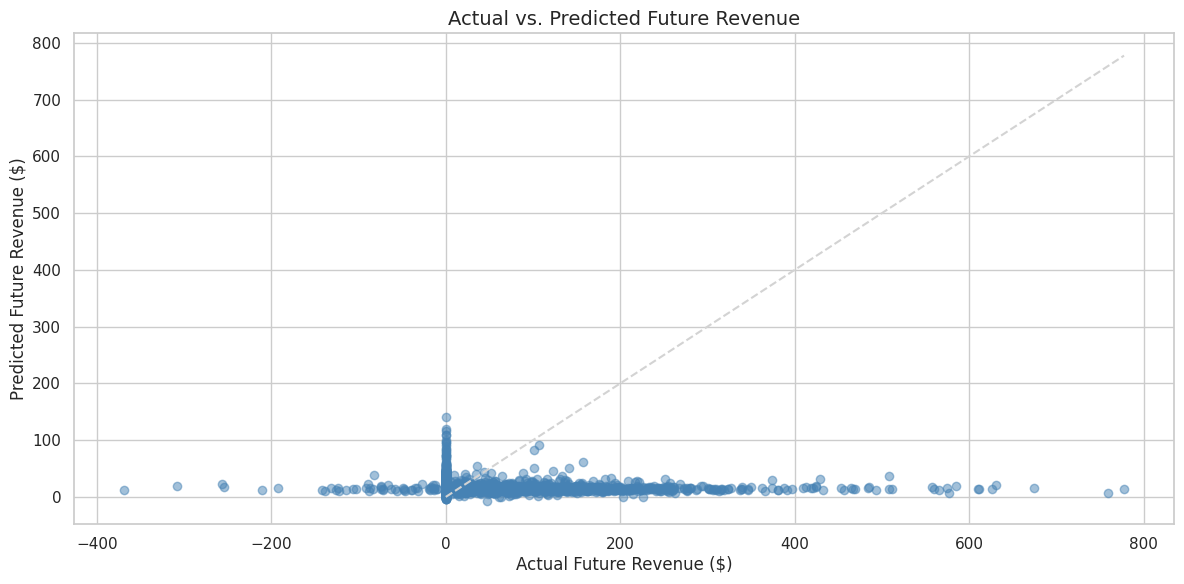

In [67]:
# Actual vs. Predicted Revenue by XGBoost Regression
fig, ax = plt.subplots(figsize = (12, 6))

ax.scatter(
    y_test,
    xgb_pred,
    alpha = 0.5,
    color = 'steelblue'
)

# Add reference line
max_value = max(
    y_test.max(),
    xgb_pred.max()
)

ax.plot(
    [0, max_value],
    [0, max_value],
    linestyle = '--',
    color = 'lightgray',
    linewidth = 1.5
)

ax.set_title(
    'Actual vs. Predicted Future Revenue',
    fontsize = 14
)
ax.set_xlabel('Actual Future Revenue ($)', fontsize = 12, labelpad = 3)
ax.set_ylabel('Predicted Future Revenue ($)', fontsize = 12, labelpad = 3)

plt.tight_layout()
plt.show()

In [68]:
# Inspect the distribution of future revenue and identify
# zero and negative revenue observations.
revenue_distribution = pd.DataFrame({
    'Training': [
        y_train.min(),
        (y_train < 0).sum(),
        (y_train == 0).sum()
    ],
    'Test': [
        y_test.min(),
        (y_test < 0).sum(),
        (y_test == 0).sum()
    ]
}, index=[
    'Minimum Revenue',
    'Negative Revenue Count',
    'Zero Revenue Count'
])

# Create a separate display table
revenue_distribution_display = revenue_distribution.copy().astype(object)

# Format minimum revenue as currency
revenue_distribution_display.loc['Minimum Revenue'] = (
    revenue_distribution.loc['Minimum Revenue']
    .map(lambda x: f'-${abs(x):,.2f}' if x < 0 else f'${x:,.2f}')
)

# Format counts as integers
for row in ['Negative Revenue Count', 'Zero Revenue Count']:
    revenue_distribution_display.loc[row] = (
        revenue_distribution.loc[row]
        .map(lambda x: f'{x:,.0f}')
    )

display(revenue_distribution_display)

,Training,Test
Minimum Revenue,-$531.75,-$368.41
Negative Revenue Count,175,51
Zero Revenue Count,"35,293","8,732"


## 3.2 Two-Stage Future Revenue Prediction

The future revenue target contains a large number of zero values because many customers do not make a purchase during the prediction period.

To address this structure, a two-stage modeling approach separates:

**Stage 1 — Purchase Prediction**

Predict whether a customer will make at least one purchase during the prediction period.

**Stage 2 — Revenue Prediction Among Buyers**

Predict the amount of future revenue conditional on a purchase occurring.

The conceptual expected revenue is:

> **Expected Future Revenue = Purchase Probability × Predicted Revenue Among Buyers**

This approach separates the questions of whether a customer will purchase and how much the customer will spend.

In [69]:
# Identify actual purchases after the cutoff date.
# Exclude refund records when defining purchase behavior.

future_purchase_trans = future_trans.loc[
    ~future_trans['is_refund']
].copy()

future_purchase = (
    future_purchase_trans
    .groupby('customer_id')
    .agg(
        future_transactions=('transaction_id', 'nunique')
    )
    .reset_index()
)

future_purchase['future_purchase'] = (
    future_purchase['future_transactions'] > 0
).astype(int)

In [70]:
# Keep all customers in the modeling dataset.
model_data = model_data.merge(
    future_purchase[['customer_id', 'future_purchase']],
    on = 'customer_id',
    how = 'left'
)

model_data['future_purchase'] = (
    model_data['future_purchase']
    .fillna(0)
    .astype(int)
)

In [71]:
print("\nFuture purchase distribution:")

print(
    model_data['future_purchase']
    .value_counts(normalize = True)
    .sort_index()
)


Future purchase distribution:
future_purchase
0    0.850348
1    0.149652
Name: proportion, dtype: float64


### 3.2.1 Prepare Two-Stage Targets

In [72]:
# Count buyers and non-buyers
purchase_counts = (
    model_data['future_purchase']
    .value_counts()
    .rename(index = {
        0: 'No Purchase',
        1: 'Purchase'
    })
)

purchase_counts

future_purchase
No Purchase    44230
Purchase        7784
Name: count, dtype: int64

### 3.2.2 Define Features and Targets

The same historical customer features are used as predictors in both stages.

All predictors are calculated using information available before the cutoff date.

### Targets

- future_purchase: Whether the customer made at least one purchase during the prediction period

- future_revenue: Revenue generated during the prediction period

In [73]:
# Historical customer features
# Customer tenure before the cutoff date
cust_features['first_transaction_date'] = (
    purchase_trans.groupby('customer_id')['timestamp']
    .min()
)
cust_features['tenure_days'] = (
    cutoff_date
    - cust_features['first_transaction_date']
).dt.days

cust_features['trans_per_month'] = (
    cust_features['total_trans'] /
    (cust_features['tenure_days'] / 30 + 1)
)

recent_90d = purchase_trans[
    purchase_trans['timestamp'] >
    cutoff_date - pd.Timedelta(days = 90)
].groupby('customer_id').agg(
    trans_90d = ('transaction_id', 'nunique'),
    revenue_90d = ('gross_revenue', 'sum')
).reset_index()

cust_features = cust_features.merge(
    recent_90d,
    on = 'customer_id',
    how = 'left'
)

# Identify customers with no historical purchase records
cust_features['no_hist_purchase'] = (
    cust_features['first_transaction_date'].isna()
).astype(int)

cust_features[
['tenure_days', 'trans_per_month', 
 'trans_90d', 'revenue_90d']
] = (
    cust_features[['tenure_days', 'trans_per_month', 
                   'trans_90d', 'revenue_90d']
    ]
    .fillna(0)
)

In [74]:
features = [
    'recency_days',
    'total_trans',
    'avg_trans_value',
    'total_quantity',
    'acquisition_channel',
    'country',
    'campaign_views',
    'discount_rate',
    'tenure_days',
    'trans_per_month',
    'trans_90d',
    'revenue_90d',
    'no_hist_purchase'    
]

model_data = model_data.merge(
    cust_features[
        [
            'customer_id',
            'tenure_days',
            'trans_per_month',
            'trans_90d',
            'revenue_90d',
            'no_hist_purchase'
        ]
    ],
    on='customer_id',
    how='left'
)

# Stage 1 target
target_purchase = 'future_purchase'

# Stage 2 target
target_revenue = 'future_revenue'

X = model_data[features]

y_purchase = model_data[target_purchase]
y_revenue = model_data[target_revenue]

display(
    model_data[features + [target_purchase, target_revenue]]
    .head()
    .style.format({
        'recency_days': '{:,.0f}',
        'total_trans': '{:,.0f}',
        'avg_trans_value': '${:,.2f}',
        'total_quantity': '{:,.0f}',
        'campaign_views': '{:,.0f}',
        'discount_rate': '{:.0%}',
        'tenure_days': '{:,.0f}',
        'trans_per_month': '{:.2f}',
        'trans_90d': '{:,.0f}',
        'revenue_90d': '${:,.2f}',
        'no_hist_purchase': '{:.0f}',
        'future_purchase': '{:.0f}',
        'future_revenue': '${:,.2f}'
    })
)

,recency_days,total_trans,avg_trans_value,total_quantity,acquisition_channel,country,campaign_views,discount_rate,tenure_days,trans_per_month,trans_90d,revenue_90d,no_hist_purchase,future_purchase,future_revenue
0,881,1,$60.09,1,Organic,IN,4,100%,0,0.00,0,$0.00,1,0,$0.00
1,450,1,$65.63,1,Paid Search,BR,4,100%,0,0.00,0,$0.00,1,0,$0.00
2,576,1,$71.90,1,Organic,US,10,0%,881,0.03,0,$0.00,0,0,$0.00
3,373,1,$76.14,1,Paid Search,IN,13,0%,0,0.00,0,$0.00,1,0,$0.00
4,320,1,$97.28,1,Organic,BR,7,100%,0,0.00,0,$0.00,1,0,$0.00


### Train-Test Split

In [75]:
from sklearn.model_selection import train_test_split

# Create customer_level train/test split
X_train, X_test, y_purchase_train, y_purchase_test, \
y_revenue_train, y_revenue_test = train_test_split(
    X,
    y_purchase,
    y_revenue,
    test_size = 0.2,
    random_state = 42
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))

Training customers: 41611
Testing customers: 10403


In [76]:
numeric_features = [
    'recency_days',
    'total_trans',
    'avg_trans_value',
    'total_quantity',
    'discount_rate',
    'campaign_views',
    'tenure_days',
    'trans_per_month',
    'trans_90d',
    'revenue_90d',
    'no_hist_purchase' 
]

categorical_features = [
    'acquisition_channel',
    'country'
]

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numeric_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformation to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (41611, 23)
Processed testing shape: (10403, 23)


### Stage 1 - Purchase Prediction
The first stage predicts whether a customer will make at least one purchase during the 180-day prediction period.

This is a binary classification problem:

- `1` = customer makes a future purchase
- `0` = customer does not make a future purchase

Logistic Regression is used as a baseline model, while XGBoost is used to capture nonlinear relationships.

### Logistic Regression

In [77]:
# Train Logistic Regression classifier
logistic_model = LogisticRegression(
    max_iter = 1000,
    class_weight = 'balanced',
    random_state = 42
)

logistic_model.fit(
    X_train_processed,
    y_purchase_train
)

# Predict purchase probability
purchase_prob_lr = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

# Predict purchase class
purchase_pred_lr = (
    purchase_prob_lr >= 0.5
).astype(int)

### XGBoost Classifier

In [78]:
# Calculate class imbalance ratio
negative_count = (y_purchase_train == 0).sum()
positive_count = (y_purchase_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale pos weight:", scale_pos_weight)

# Train XGBoost classifier
xgb_classifier = XGBClassifier(
    n_estimators = 150,
    max_depth = 5,
    learning_rate = 0.1,
    scale_pos_weight = scale_pos_weight,
    random_state = 42,
    eval_metric = 'logloss'
)

xgb_classifier.fit(
    X_train_processed,
    y_purchase_train
)

# Predict purchase probability
purchase_prob_xgb = xgb_classifier.predict_proba(
    X_test_processed
)[:, 1]

# Predict purchase class
purchase_pred_xgb = (
    purchase_prob_xgb >= 0.5
).astype(int)

Scale pos weight: 5.757226372198766


### Evaluate Purchase Prediction

The classification models are evaluated using Precision, Recall, F1-score, and ROC-AUC.

- Precision measures how many predicted buyers actually purchased.
- Recall measures how many actual buyers were identified.
- F1-score balances precision and recall.
- ROC-AUC measures the model's ability to rank customers by future purchase likelihood.

ROC-AUC is particularly useful when evaluating customer ranking performance under class imbalance.

In [79]:
# Evaluation function for classification
def evaluate_classifier(y_true, y_pred, y_prob, model_name):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division = 0)
    recall = recall_score(y_true, y_pred, zero_division = 0)
    f1 = f1_score(y_true, y_pred, zero_division = 0)
    auc = roc_auc_score(y_true, y_prob)

    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'ROC-AUC': auc
    }

# Evaluate both classifiers
classification_results = pd.DataFrame([
    evaluate_classifier(
        y_purchase_test,
        purchase_pred_lr,
        purchase_prob_lr,
        'Logistic Regression'
    ),
     evaluate_classifier(
         y_purchase_test,
         purchase_pred_xgb,
         purchase_prob_xgb,
         'XGBoost'
     )
])

classification_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.526290,0.155036,0.456335,0.231441,0.496722
1,XGBoost,0.581659,0.157193,0.384379,0.223135,0.506287


In [80]:
# Evaluate different probability thresholds
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:    
    pred = (
        purchase_prob_xgb >= threshold
    ).astype(int)
    
    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_purchase_test,
            pred,
            zero_division=0
        ),
        'Recall': recall_score(
            y_purchase_test,
            pred,
            zero_division = 0
        ),
        'F1': f1_score(
            y_purchase_test,
            pred,
            zero_division = 0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,Threshold,Precision,Recall,F1
0,0.10,0.156259,0.998770,0.270239
1,0.15,0.156560,0.998770,0.270689
2,0.20,0.156474,0.994465,0.270401
3,0.25,0.156524,0.987085,0.270202
4,0.30,0.157260,0.978475,0.270970
5,0.35,0.157290,0.950800,0.269926
6,0.40,0.156913,0.895449,0.267033
7,0.50,0.157193,0.384379,0.223135


### Stage 2 — Revenue Prediction Among Buyers

The second stage predicts future revenue only among customers who actually made a purchase during the prediction period.

This conditional regression focuses on the magnitude of customer spending after a purchase occurs.

In [81]:
# Identify customers who actually purchased in the future period
buyer_mask_train = y_purchase_train == 1

X_train_buyers = X_train_processed[
    buyer_mask_train
]

y_revenue_train_buyers = y_revenue_train[
    buyer_mask_train
]

buyer_mask_test = y_purchase_test == 1

X_test_buyers = X_test_processed[
    buyer_mask_test
]

y_revenue_test_buyers = y_revenue_test[
    buyer_mask_test
]

print(
    "Training customers with future purchases:",
    len(y_revenue_train_buyers)
)

print(
    "Testing customers with future purchases:",
    len(y_revenue_test_buyers)
)

Training customers with future purchases: 6158
Testing customers with future purchases: 1626


In [82]:
# Train Linear Regression on future revenue among buyers.
revenue_lr = LinearRegression()

revenue_lr.fit(
    X_train_buyers,
    y_revenue_train_buyers
)

# Predict future revenue among test-set buyers.
revenue_pred_lr = revenue_lr.predict(
    X_test_buyers
)

In [83]:
# Train XGBoost on revenue
revenue_xgb = XGBRegressor(
    n_estimators = 150,
    max_depth = 5,
    learning_rate = 0.1,
    random_state = 42
)

revenue_xgb.fit(
    X_train_buyers,
    y_revenue_train_buyers
)

# Predict future revenue among test-set buyers.
revenue_pred_xgb = revenue_xgb.predict(
    X_test_buyers
)

In [84]:
# Evaluate Stage 2 only among actual future buyers in the test set

def evaluate_regression(
    y_true,
    y_pred,
    model_name
):
    
    mae = mean_absolute_error(
        y_true,
        y_pred
    )
    
    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )
    
    r2 = r2_score(
        y_true,
        y_pred
    )
    
    return {
        'Model': model_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    }

revenue_results = pd.DataFrame([    
    evaluate_regression(
        y_revenue_test_buyers,
        revenue_pred_lr,
        'Linear Regression'
    ),
    
    evaluate_regression(
        y_revenue_test_buyers,
        revenue_pred_xgb,
        'XGBoost'
    )
])

revenue_results

# Compare Stage 2 model performance.
revenue_results.sort_values('MAE')

,Model,MAE,RMSE,R2
0,Linear Regression,67.006783,95.488492,-0.007236
1,XGBoost,71.281637,102.001311,-0.149319


### 3.3 Model Interpretation
Feature importance is used to identify which historical customer features the XGBoost model relies on most when predicting future revenue.

These importance scores indicate model reliance rather than causal importance.

In [85]:
# Extract XGBoost feature importance to understand which
# historical features the model relies on most.
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': revenue_xgb.feature_importances_
}).sort_values(
    'importance',
    ascending = False
)

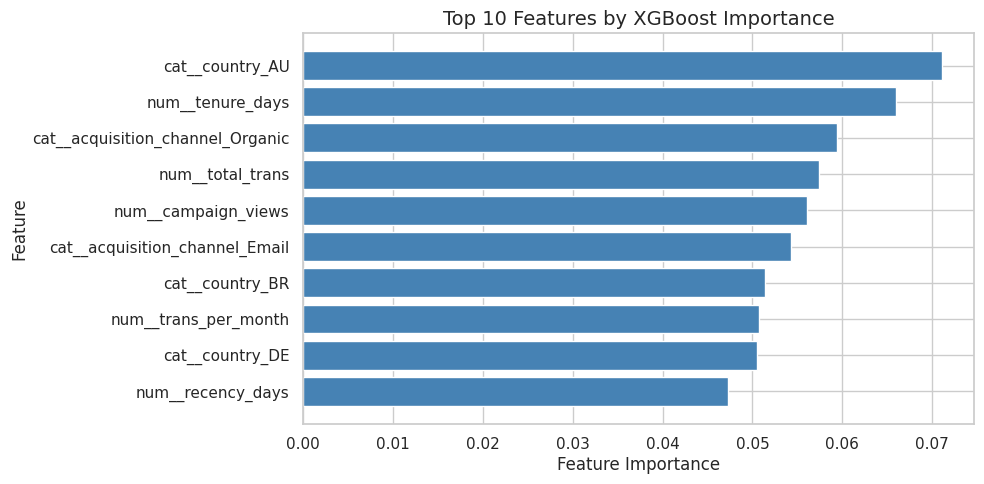

In [86]:
# Plot top 10 features by importance
top10_features = feature_importance.head(10).sort_values(
    'importance',
    ascending = True
)

fig, ax = plt.subplots(figsize = (10, 5))

ax.barh(
    top10_features['feature'],
    top10_features['importance'],
    color = 'steelblue'
)

ax.set_xlabel('Feature Importance', fontsize = 12, labelpad = 3)
ax.set_ylabel('Feature', fontsize = 12, labelpad = 3)

ax.set_title(
    'Top 10 Features by XGBoost Importance',
    fontsize = 14
)

plt.tight_layout()
plt.show()

## Module Summary

### Key Findings

- A temporal cutoff was used to separate historical features from the future prediction period and prevent data leakage.
- One-stage regression models showed limited predictive performance for future revenue.
- The two-stage framework separated future purchase probability from revenue magnitude among buyers.
- Stage 1 models showed limited ability to distinguish future buyers from non-buyers based on the available historical features.
- Stage 2 models also showed limited predictive performance among future buyers.

### Business Implications

The available historical customer features provide limited predictive signal for short-term future revenue in this dataset. Additional behavioral, temporal, product-level, and engagement features may be required to improve future revenue prediction.

These results also highlight an important analytical point: a more complex model does not necessarily provide better business value when the underlying features contain limited predictive signal.

# Overall Conclusions & Business Recommendations

## Key Findings

- Category Performance: Electronics is the largest revenue-driving category, contributing a substantial share of total GMV.
- Product Funnel: The largest customer loss occurs between add-to-cart and purchase, making this the primary funnel optimization opportunity.
- Brand Portfolio: Revenue is relatively diversified across brands rather than concentrated in a small number of brands.
- Premium Products: Premium products generate substantially higher AOV and GMV contribution while showing similar conversion and refund rates to non-premium products.
- Discount Strategy: Higher discount levels are associated with lower revenue per transaction, while first-order discounts show limited differences in repeat-purchase rates.
- Future Revenue Prediction: Historical customer features provide limited predictive signal for short-term future revenue in the available dataset.

## Business Recommendations

1. Prioritize core categories: Continue investing in high-GMV categories while monitoring conversion and refund performance.
3. Optimize the cart-to-purchase stage: Investigate checkout friction, pricing transparency, shipping costs, payment options, and cart-recovery opportunities.
4. Maintain premium-product investment: Premium products appear to be an important revenue driver because of their substantially higher transaction value.
5. Use discounts selectively: Avoid relying on broad or deeper discounts when they do not generate a meaningful repeat-purchase advantage. Evaluate discount strategies by product category and customer segment.
6. Improve future-value prediction: Add richer behavioral and temporal features, such as recent browsing activity, product-category preferences, session behavior, and time since last engagement.

## Limitations

- Observational relationships should not be interpreted as causal effects.
- Discount exposure was not randomly assigned, so discount effects cannot be identified causally.
- Funnel analysis is based on unique customer reach at each stage rather than strictly ordered event sequences.
- Future revenue prediction is limited by the available historical features and prediction horizon.

# Appendix: Experiment Data Quality Assessment

This appendix evaluates whether the experiment_group field is suitable for customer-level A/B testing.

## Experiment Group Assignment Validation

Before using experiment_group for A/B testing, validate whether customers remain consistently assigned to a single experiment group.

A valid customer-level experiment requires a stable assignment mechanism so that treatment exposure is not repeatedly changed across events.

In [87]:
# Examine whether customers are consistently associated
# with a single experiment group across their events.

customer_group_distribution = (
    events
    .groupby(['customer_id', 'experiment_group'])
    .size()
    .unstack(fill_value = 0)
)

customer_group_distribution['total_events'] = (
    customer_group_distribution.sum(axis = 1)
)

customer_group_distribution['control_share'] = (
    customer_group_distribution['Control']
    / customer_group_distribution['total_events']
)

customer_group_distribution['variant_a_share'] = (
    customer_group_distribution['Variant_A']
    / customer_group_distribution['total_events']
)

customer_group_distribution['variant_b_share'] = (
    customer_group_distribution['Variant_B']
    / customer_group_distribution['total_events']
)

display(
    customer_group_distribution.head().style.format({
        'Control': '{:,.0f}',
        'Variant_A': '{:,.0f}',
        'Variant_B': '{:,.0f}',
        'total_events': '{:,.0f}',
        'control_share': '{:.1%}',
        'variant_a_share': '{:.1%}',
        'variant_b_share': '{:.1%}'
    })
)

experiment_group,Control,Variant_A,Variant_B,total_events,control_share,variant_a_share,variant_b_share
customer_id,,,,,,,
1,10,5,3,18,55.6%,27.8%,16.7%
2,11,4,4,19,57.9%,21.1%,21.1%
3,11,1,2,14,78.6%,7.1%,14.3%
4,13,6,4,23,56.5%,26.1%,17.4%
5,6,3,2,11,54.5%,27.3%,18.2%


In [88]:
display(
    customer_group_distribution[
        [
            'control_share',
            'variant_a_share',
            'variant_b_share'
        ]
    ]
    .mean()
    .to_frame(name = 'Average Share')
    .style.format('{:.1%}')
)

,Average Share
experiment_group,
control_share,59.9%
variant_a_share,20.1%
variant_b_share,20.0%


In [89]:
# Review overall experiment-group allocation.
print(events['experiment_group'].value_counts(dropna = False))

# Count the number of distinct experiment groups associated
# with each customer.
group_per_customer = (
    events
    .groupby('customer_id')['experiment_group']
    .nunique()
)

print("\nNumber of unique experiment groups per customer:")
print(group_per_customer.value_counts().sort_index())

experiment_group
Control      1198404
Variant_A     401413
Variant_B     400183
Name: count, dtype: int64

Number of unique experiment groups per customer:
experiment_group
1       37
2     3611
3    96352
Name: count, dtype: int64


In [90]:
# Inspect one customer's event history to verify whether
# experiment-group assignment remains stable over time.
sample_customer = events['customer_id'].iloc[0]

events[
    events['customer_id'] == sample_customer
][
    ['customer_id', 'timestamp', 'event_type', 'experiment_group']
].sort_values('timestamp').head(20)

,customer_id,timestamp,event_type,experiment_group
0,43812,2021-01-14 13:35:43,view,Control
553062,43812,2021-01-31 05:51:21,view,Control
1896950,43812,2021-03-05 09:48:12,click,Control
190405,43812,2021-03-26 18:48:37,add_to_cart,Variant_B
106539,43812,2021-04-01 19:51:08,view,Control
683623,43812,2021-11-12 23:20:22,add_to_cart,Control
54878,43812,2021-11-20 06:42:37,bounce,Variant_A
439523,43812,2021-12-08 17:54:25,click,Variant_B
265486,43812,2021-12-18 20:11:38,purchase,Variant_B
964590,43812,2022-01-23 07:40:55,add_to_cart,Control


In [91]:
event_group_share = pd.crosstab(
    events['event_type'],
    events['experiment_group'],
    normalize = 'index'
)

display(
    event_group_share.style.format('{:.1%}')
)

experiment_group,Control,Variant_A,Variant_B
event_type,,,
add_to_cart,60.1%,20.1%,19.8%
bounce,60.3%,20.1%,19.6%
click,60.0%,20.2%,19.8%
purchase,55.1%,20.4%,24.5%
view,60.2%,20.0%,19.8%


## Key Finding

- The experiment_group field is assigned at the event level rather than consistently at the customer level.
- In the current dataset, 96,352 of 100,000 customers are associated with all three experiment groups, while only 37 customers are associated with a single group.
- Therefore, experiment_group should not be used directly for a conventional customer-level A/B test without reconstructing a stable assignment mechanism.
- This data-quality check prevents potentially invalid conclusions from being drawn from the experiment field.